# Visión por Computador - Práctica 2 - Deep Learning en Computer Vision

#### 15 puntos   |   Fecha de entrega: 7 de Diciembre, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2526.ugr.es/

### Estudiante: Jose María Martín Martín



## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.






### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2526.ugr.es/mod/folder/view.php?id=95307):
-  Introducción a Python: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/2.%20Introducción%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf (y Notebook asociado: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Algunas%20ideas%20sobre%20cómo%20elaborar%20un%20informe%20académico-científico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2526.ugr.es/pluginfile.php/243164/mod_folder/content/0/Ejemplo_Otsu.ipynb

<font color='blue'>El objetivo de esta práctica es aprender a diseñar, implementar, entrenar y utilizar (es decir, aplicar en inferencia) redes neuronales convolucionales en tareas de visión por computador (clasificación y regresión en imágenes) usando fastai (https://docs.fast.ai/).

<font color='blue'>Se proporciona una guía de ayuda (`P2_HG.ipynb`) para, entre otras cosas, saber cómo:
1. realizar funciones básicas de lectura de datos, entrenamiento y optimización;
2. crear gráficos para la evolución del error de clasificación en
los conjuntos de entrenamiento y validación;
3. y calcular el error de clasificación en el conjunto de prueba.

In [ ]:
# The first thing we should do is to apply hardware acceleration via GPU. So, we have to go to Editar - Configuracion del Cuaderno - Acelerador por Hardware GPU

# Now we SET UP Fastai
!pip install -Uqq fastbook
!pip install nbdev
import fastbook
fastbook.setup_book()
import fastai
import fastcore
print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')
from nbdev.showdoc import *
from fastai.vision.all import *

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 50.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 7.0 MB/s eta 0:00:00
Mounted at /content/gdrive
fastcore version 1.9.2 installed
fastai version 2.8.6 installed


In [ ]:
# Function to display evaluation metrics
# Developed by Ignacio Oguiza: https://forums.fast.ai/t/plotting-metrics-after-learning/69937

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.stack(self.values)
    names = self.metric_names[1:-1]
    n = len(names) - 1
    if nrows is None and ncols is None:
        nrows = int(math.sqrt(n))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None: nrows = int(np.ceil(n / ncols))
    elif ncols is None: ncols = int(np.ceil(n / nrows))
    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = [ax if i < n else ax.set_axis_off() for i, ax in enumerate(axs.flatten())][:n]
    for i, (name, ax) in enumerate(zip(names, [axs[0]] + axs)):
        ax.plot(metrics[:, i], color='#1f77b4' if i == 0 else '#ff7f0e', label='valid' if i > 0 else 'train')
        ax.set_title(name if i > 1 else 'losses')
        ax.legend(loc='best')
    plt.show()



---



---



---



# <font color='blue'>**Ejercicio 1: BaseNet en 50 clases de CIFAR100 (5 puntos)**





## <font color='blue'> Creación, entrenamiento y validación del modelo (4 puntos)

<font color='blue'>**Dataset:**
En este ejercicio, trabajaremos con parte del conjunto de datos $\textit{CIFAR100}$ (https://www.cs.toronto.edu/~kriz/cifar.html). Este conjunto de datos consta de $60000$ imágenes en color de $32\times32\times3$ (RGB) que representan $100$ clases diferentes ($600$ imágenes por clase). Hay $50000$ imágenes para entrenamiento y $10000$ para test. No obstante, para el desarrollo del ejercicio solo consideraremos $50$ clases (de $100$). Por lo tanto, el conjunto de entrenamiento tendrá $25000$ imágenes y el conjunto de prueba $5000$ imágenes. Los alumnos deben emplear el $10\%$ del conjunto de entrenamiento para  validación.

<font color='blue'>**Modelo BaseNet:**
Comenzamos creando un modelo base llamado *BaseNet* que consta de dos bloques convolucionales (Conv+Sigmoid y Conv+Tanh) separados por un proceso de *subsampling* (MaxPooling), y una cabeza compuesta por tres capas completamente conectadas (FC) (también llamadas capas densas). La arquitectura precisa se define en la siguiente tabla:

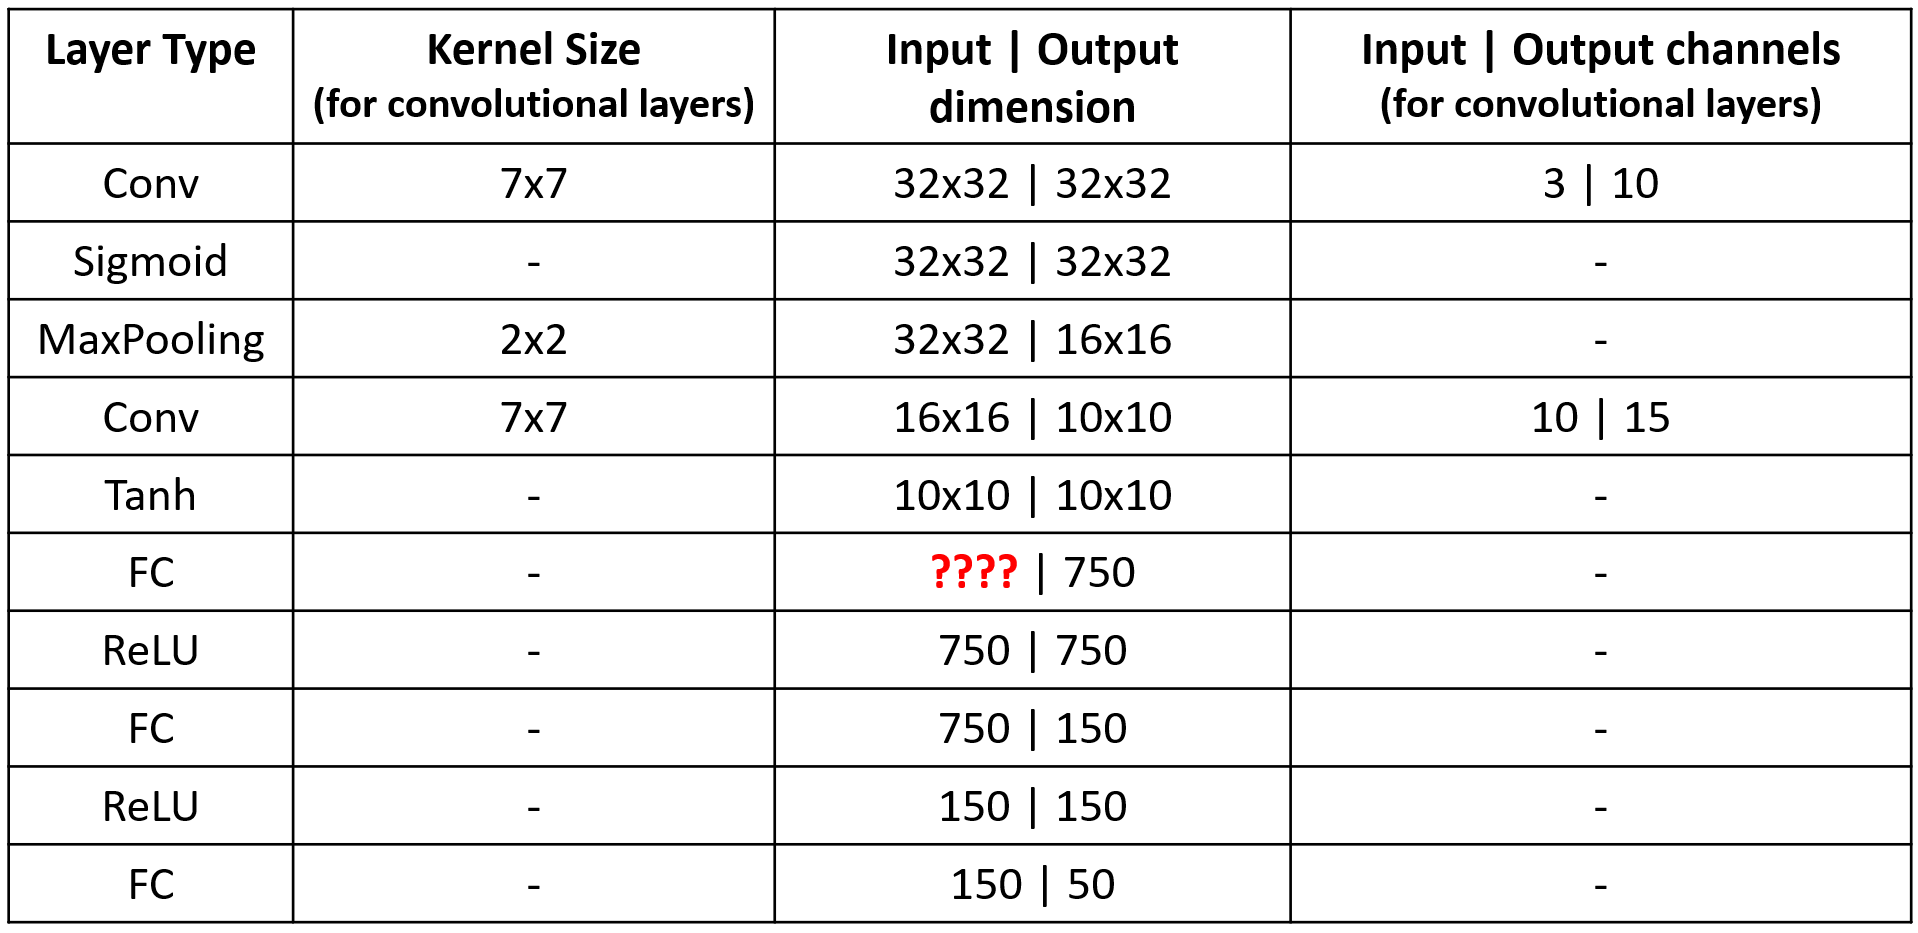

<font color='blue'>Nótese que el tamaño de entrada a la primera FC layer se marca con interrogantes. Esto se debe a que es el alumnado el que debe calcular el valor correspondiente y explicar el cálculo realizado.

<font color='blue'>Los alumnos deben:
1. Crear el código para el modelo *BaseNet* empleando fastai/PyTorch.
2. Explicar y describir cada una de las capas de la arquitectura *BaseNet*, así como las decisiones de implementación tomadas. Por ejemplo:
    - <font color='blue'>¿Qué función de pérdida se debería emplear: `CrossEntropyLoss()`, `CrossEntropyLossFlat()` o alguna otra?
    - ¿Se debería incorporar manualmente, en la definición de la red, la función de activación de la capa final (`nn.Softmax()`)? ¿Por qué?
    - ¿Cómo se ha calculado la dimensionalidad de entrada de la primera FC layer?
3. Desglosar detalladamente el número de parámetros de esta arquitectura, y cuánto contribuye cada capa a dicho número total. Se debe hacer un `summary()` del modelo para verificar que la arquitectura se ha construido adecuadamente y que el número de parámetros es correcto (es decir, se corresponde con lo calculado previamente).
4. Entrenar el modelo, sin aplicar la política de 1 ciclo de Leslie N. Smith, con _SGD_ (`lr=0.01`, `momentum=0.9`), e incluyendo _early stopping_ monitorizando la _loss_ en validación con una paciencia de $5$ durante $25$ épocas, y *batch size* de $128$ ejemplos. A continuación, se debe evaluar el rendimiento por medio de emplear/mostrar/analizar:
    - <font color='blue'>la matriz de confusión en entrenamiento, validación y test;
    - la _accuracy_ en entrenamiento, validación y test;
    - y la evolución, por épocas, tanto de la función de pérdida (en entrenamiento y validación) como de la _accuracy_ (en validación) y el _F1 score (Macro)_ (en validación).



In [ ]:
# We get the CIFAR100 dataset
path = untar_data(URLs.CIFAR_100,force_download=True)

In [ ]:
# The CIFAR_100 dataset, as well as the MNIST dataset, follows a common layout for machine learning datasets:
# separate folders for the training set and the validation set (and/or test set).
# Let's see what's inside both the training and test sets
print(path)
print(path.ls())
print((path/'train').ls())
print((path/'test').ls())
# train_classes = (path/'train').ls()
# test_classes = (path/'test').ls()
train_classes = sorted((path/'train').ls(), key=lambda p: p.name.casefold())
test_classes  = sorted((path/'test').ls(),  key=lambda p: p.name.casefold())
print([p.name for p in train_classes])  # <-- sorted names
print([p.name for p in test_classes])   # <-- sorted names
print(len(train_classes))

/root/.fastai/data/cifar100
[Path('/root/.fastai/data/cifar100/train'), Path('/root/.fastai/data/cifar100/test')]
[Path('/root/.fastai/data/cifar100/train/food_containers'), Path('/root/.fastai/data/cifar100/train/vehicles_1'), Path('/root/.fastai/data/cifar100/train/fish'), Path('/root/.fastai/data/cifar100/train/vehicles_2'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals'), Path('/root/.fastai/data/cifar100/train/household_electrical_devices'), Path('/root/.fastai/data/cifar100/train/large_man-made_outdoor_things'), Path('/root/.fastai/data/cifar100/train/insects'), Path('/root/.fastai/data/cifar100/train/reptiles'), Path('/root/.fastai/data/cifar100/train/fruit_and_vegetables'), Path('/root/.fastai/data/cifar100/train/trees'), Path('/root/.fastai/data/cifar100/train/small_mammals'), Path('/root/.fastai/data/cifar100/train/medium_mammals'), Path('/root/.fastai/data/cifar100/train/large_carnivores'), Path('/root/.fastai/data/cifar100/train/household_furniture'), Path('/root/

Vemos que hay 20 clases, pero eso no debe confundirnos. Eso son solo las 20 superclases en que está subdividido el dataset. Véase https://github.com/fastai/dlcert2/blob/master/docs/datasets.md:
*"This dataset is just like the CIFAR-10, except it has 100 classes containing 600 images each. There are 500 training images and 100 testing images per class. **The 100 classes in the CIFAR-100 are grouped into 20 superclasses**. Each image comes with a "fine" label (the class to which it belongs) and a "coarse" label (the superclass to which it belongs)."*

In [ ]:
# Queremos verificar que dentro de cada una de las 20 superclases hay 5 clases,
# lo que da las 100 clases que hay. También queremos verificar que el número de imágenes
# es correcto
print('Clases dentro de la primera superclase (',train_classes[0],'): ', train_classes[0].ls())
for i in range(20):
  print('Número de clases dentro de superclase ',i,': ', len(train_classes[i].ls()))
files_train = get_image_files(path/'train')
files_test = get_image_files(path/'test')
print('Total training images: ', len(files_train))
print('Total test images: ', len(files_test))

Clases dentro de la primera superclase ( /root/.fastai/data/cifar100/train/aquatic_mammals ):  [Path('/root/.fastai/data/cifar100/train/aquatic_mammals/dolphin'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/beaver'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/otter'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/seal'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/whale')]
Número de clases dentro de superclase  0 :  5
Número de clases dentro de superclase  1 :  5
Número de clases dentro de superclase  2 :  5
Número de clases dentro de superclase  3 :  5
Número de clases dentro de superclase  4 :  5
Número de clases dentro de superclase  5 :  5
Número de clases dentro de superclase  6 :  5
Número de clases dentro de superclase  7 :  5
Número de clases dentro de superclase  8 :  5
Número de clases dentro de superclase  9 :  5
Número de clases dentro de superclase  10 :  5
Número de clases dentro de superclase  11 :  5
Número de clases dentro

Ahora nos quedamos con $50$ clases / $10$ superclases (para evitar que no siempre se escojan las mismas, las fijamos manualmente al comienzo de la siguiente celda).

In [ ]:
import shutil
keep_names = {'aquatic_mammals', 'fish', 'flowers', 'fruit_and_vegetables',
              'insects', 'large_carnivores',  'large_omnivores_and_herbivores',
              'reptiles', 'vehicles_1', 'vehicles_2'}
train_classes = sorted((path/'train').ls(), key=lambda p: p.name.casefold())
test_classes  = sorted((path/'test').ls(),  key=lambda p: p.name.casefold())

print('SUPERCLASES ELIMINADAS:')
print('Training Set: ')
for p in train_classes:
    if p.name not in keep_names:
        print(p)
        shutil.rmtree(p)
print('Test Set: ')
for p in test_classes:
    if p.name not in keep_names:
        print(p)
        shutil.rmtree(p)

print('SUPERCLASES CONSERVADAS:')
print('Training Set: ')
for p in train_classes:
    if p.name in keep_names:
        print(p)
print('Test Set: ')
for p in test_classes:
    if p.name in keep_names:
        print(p)


SUPERCLASES ELIMINADAS:
Training Set: 
/root/.fastai/data/cifar100/train/food_containers
/root/.fastai/data/cifar100/train/household_electrical_devices
/root/.fastai/data/cifar100/train/household_furniture
/root/.fastai/data/cifar100/train/large_man-made_outdoor_things
/root/.fastai/data/cifar100/train/large_natural_outdoor_scenes
/root/.fastai/data/cifar100/train/medium_mammals
/root/.fastai/data/cifar100/train/non-insect_invertebrates
/root/.fastai/data/cifar100/train/people
/root/.fastai/data/cifar100/train/small_mammals
/root/.fastai/data/cifar100/train/trees
Test Set: 
/root/.fastai/data/cifar100/test/food_containers
/root/.fastai/data/cifar100/test/household_electrical_devices
/root/.fastai/data/cifar100/test/household_furniture
/root/.fastai/data/cifar100/test/large_man-made_outdoor_things
/root/.fastai/data/cifar100/test/large_natural_outdoor_scenes
/root/.fastai/data/cifar100/test/medium_mammals
/root/.fastai/data/cifar100/test/non-insect_invertebrates
/root/.fastai/data/cifar

Ahora intentamos verificar si las hemos eliminado realmente.

In [ ]:
print(path)
train_classes = (path/'train').ls()
test_classes = (path/'test').ls()
print(len(train_classes))
print(len(test_classes))

/root/.fastai/data/cifar100
10
10


Y que el número de ejemplos en training y test es el correcto.

In [ ]:
print('Clases dentro de la primera superclase (',train_classes[0],'): ', train_classes[0].ls())
files_train = get_image_files(path/'train')
files_test = get_image_files(path/'test')
print('Total training images: ', len(files_train))
print('Total test images: ', len(files_test))

Clases dentro de la primera superclase ( /root/.fastai/data/cifar100/train/vehicles_1 ):  [Path('/root/.fastai/data/cifar100/train/vehicles_1/train'), Path('/root/.fastai/data/cifar100/train/vehicles_1/bicycle'), Path('/root/.fastai/data/cifar100/train/vehicles_1/pickup_truck'), Path('/root/.fastai/data/cifar100/train/vehicles_1/bus'), Path('/root/.fastai/data/cifar100/train/vehicles_1/motorcycle')]
Total training images:  25000
Total test images:  5000


Podemos observar que ahora tenemos el dataset tal y como nos interesa, con $25000$ imágenes de entrenamiento y $5000$ de test.

Ahora vamos a proceder a cargar los datos de entrenamiento. Para ello hacemos uso de DataLoaders y DataBlock. Tenemos que tener en cuenta las siguientes cosas:
*   En blocks, debemos usar **ImageBlocks** ( tipo de dato que usamos ) y **CategoryBlock** ( indicando que es un problema de clasificación ).
*   En get_items, seleccionamos **get_image_files** para indicar como obtener los datos, en este caso le pasaremos después la ruta de donde tomar los datos.
*   Para el splitter, tomamos el 10% para el conjunto de validación y fijamos un seed para obtener los mismos datos en todas las ejecuciones.
*   Las etiquetas se toman de parent_label.
*   Por último indicamos el tamaño de los datos en **item_tfms**, donde tomamos un size de 32 que es el original del dataset.

Numero de ejemplos de entrenamiento (una vez descartados los de validacion): 22500
Numero de ejemplos de validacion: 2500


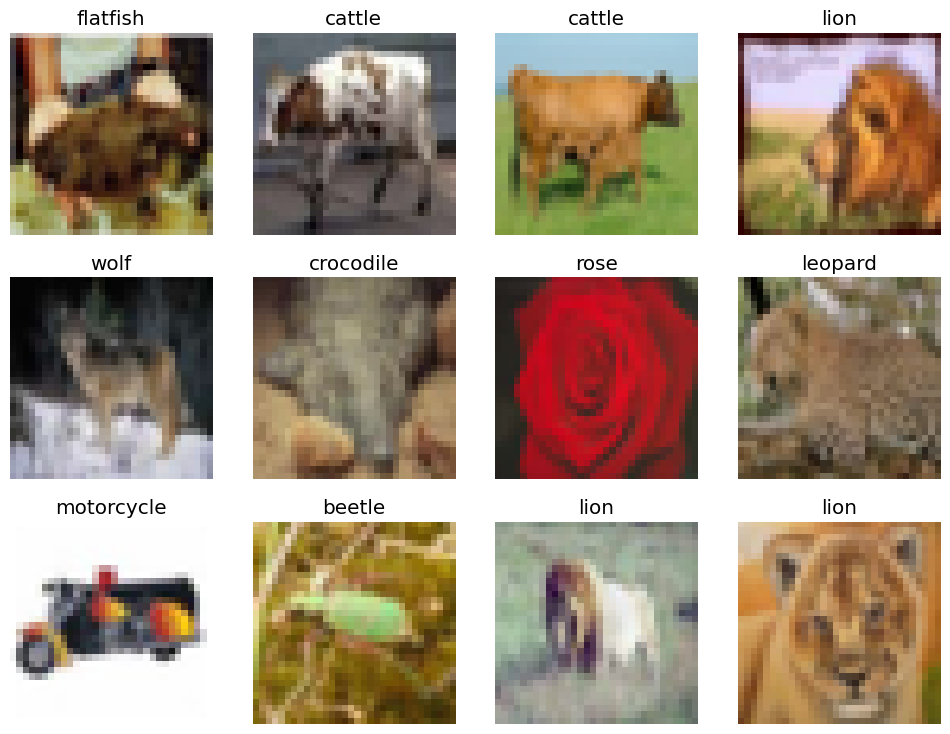

In [ ]:
CIFAR_50 = DataBlock(
    # A CUBRIR POR EL ALUMNADO
    # ImageBlock para trabajar con imgs, CategoryBlock
    # para problema de clasificacion
    blocks=(ImageBlock, CategoryBlock),
    # Funcion para tomar los datos de una ruta
    get_items=get_image_files,
    # Separador del conjunto de validacion. Se toma el 10%
    splitter=RandomSplitter(valid_pct=0.1, seed=42),
    # Metodo para tomar las etiquetas
    get_y=parent_label,
    # Tomamos los datos de 32x32
    item_tfms=[Resize(32, method = 'squish')]
)

# Le pasamos la ruta para tomar los datos y un bs de 128
dls = CIFAR_50.dataloaders(path/'train', bs=128)

dls.show_batch(max_n=12)

print('Numero de ejemplos de entrenamiento (una vez descartados los de validacion):', len(dls.train_ds))
print('Numero de ejemplos de validacion:', len(dls.valid_ds))

Example of training data


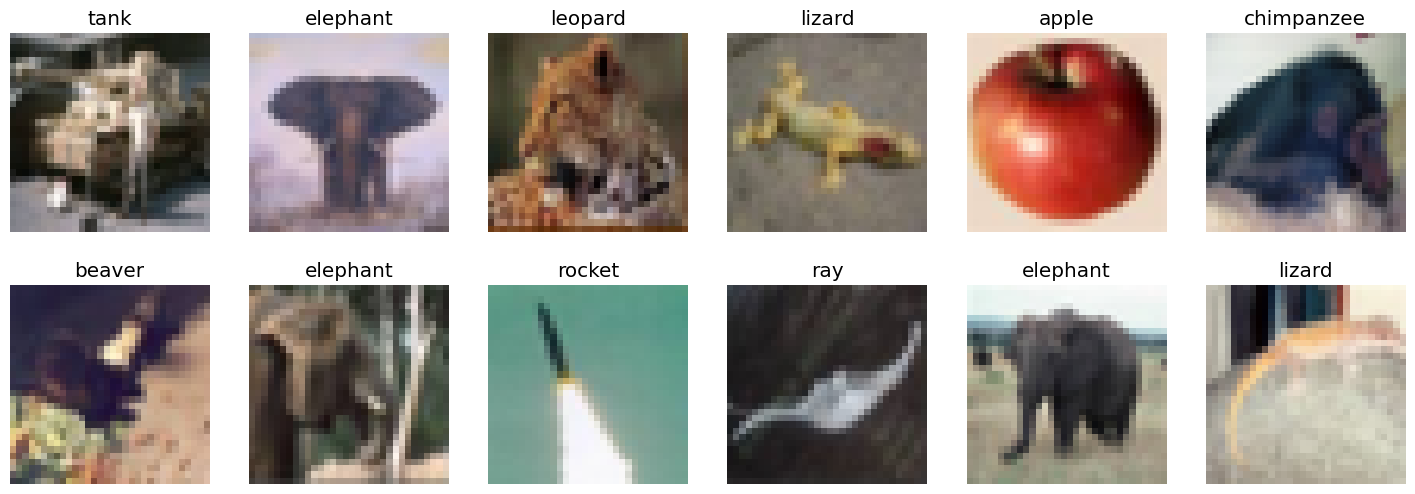

In [ ]:
print('Example of training data')
dls.train.show_batch(max_n=12, nrows=2)

Example of validation data


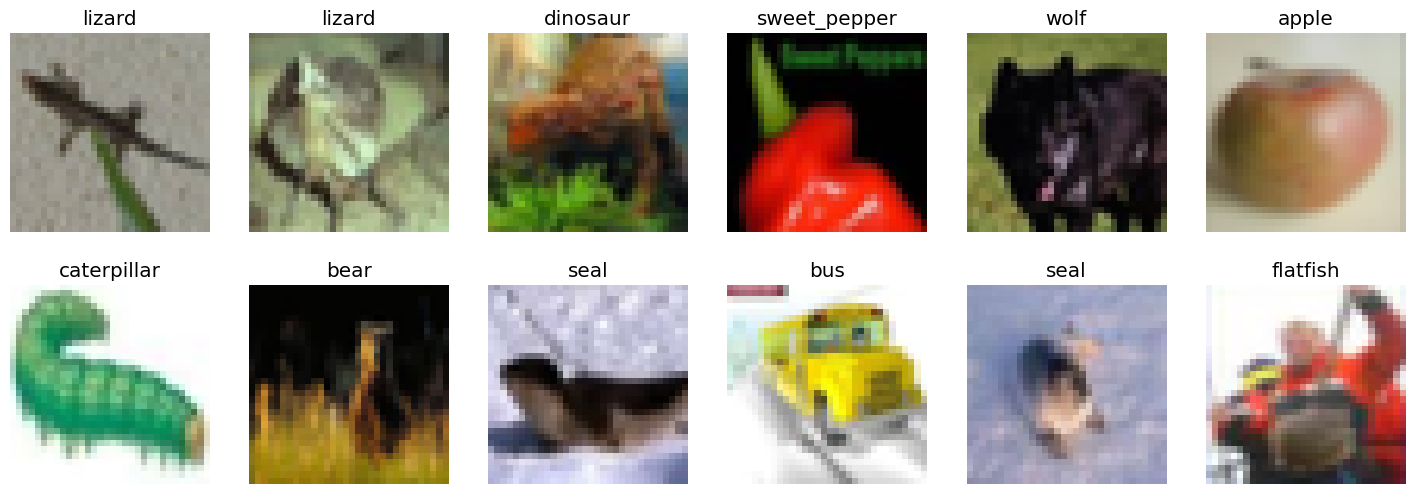

In [ ]:
print('Example of validation data')
dls.valid.show_batch(max_n=12, nrows=2)

Ahora procedemos con la creación de la red BaseNet. Para el cálculo de ciertos parámetros relativos a capas convolucionales utilizaremos la fórmula:
 **Output_size = ((input_size+2*Padding-Kernel_size)/stride) +1**.

Estas son las capas:


*   **nn.Conv2d(in_channels=3, out_channels=10, kernel_size=7, padding=3)**.
Se trata de una convolutional layer. Estas capas aplican filtros a imágenes de entrada con el fin de extraer características como por ejemplo bordes. Para la construcción de las capas no se necesita por lo general especificar el tamaño de los datos con los que se trabaja. Basta con especificar el número de canales de entrada y de salida, además del stride y del padding. Se especifica que input_shape = (32, 32, 3) y output_shape = (32, 32, 10). Por lo que sustituyendo en nuestra formula:

$$
O = \frac{ I +2*P - K}{ S} +1 ⇒
$$

$$
32 = \frac{ 32 +2*P - 7}{ S} +1 ⇒
$$

$$
S = \frac{ 25 +2*P }{ 31}
$$
Parece correcto suponer ya que no se nos dice lo contrario que **stride = 1** ya que no parece haber una razón para querer que el filtro se aplique solo a ciertos píxeles en lugar de a todos. Sabiendo esto:
$$
1 = \frac{ 25 +2*P }{ 31}  ⇒ 2P = 31-25 ⇒ P = 3
$$

*   **nn.Sigmoid()**. Se trata de la función de activación. Estas funciones se aplican sobre las salidas de la capa inmediatamente anterior. Son necesarias para aprender características no lineales de los datos. En este caso, la función escogida es la sigmoide:
$$
σ(Σ) = \frac{1}{1+e^{-Σ}}
$$


*   **nn.MaxPool2d(kernel_size=2)**. El pooling es la técnica de reducir dimensionalidad además de introducir invarianza a pequeñas traslaciones. Sirve para agrupar información local. En el caso de **max pooling** la información que se recoge de la región es el máximo de los píxeles que la componen. Como parámetro se nos indica que el tamaño de kernel ha de ser 2x2, lo que significa que agrupa bloques de 2 filas y dos columnas en un único valor ( en este caso el máximo de los 4 ). Es por esto que la entrada de esta capa es 32x32 y la salida es 16x16.
*   **nn.Conv2d(in_channels=10, out_channels=15, kernel_size=7, padding=0)**. De nuevo tenemos una capa convolucional. Para calcular el padding utilizamos la fórmula anterior ( haciendo la misma suposición de stride = 1 ).
$$
O = \frac{ I +2*P - K}{ S} +1 ⇒
10 = \frac{ 16 +2*P - 7}{ 1} +1 ⇒ 2P = 10 - 16 + 7 -1 = 0. ⇒ P = 0
$$


*   **nn.Tanh()**. Función de activación. En este caso es la tangente hiperbólica determinada por:
$$
tanh(Σ) = \frac{e^{Σ}- e^{-Σ}}{e^{Σ}+e^{-Σ}}
$$
*   **nn.Flatten().** Esta función no se especifica en la definición de la red. Sin embargo, su inclusión es necesaria, pues precede a una capa densa y esta trabaja con vectores 1D. Esta función aplana los datos de entrada a un vector 1D.


*   **nn.Linear(start_dim=1500, end_dim=750)**. Es la capa densa ( o fully connected ). Para el cálculo del parámetro **input_size** de la capa fully-connected, tenemos que tener en cuenta que los datos que son la salida de cada capa, tienen unas dimensiones **( Height, Width, Channels )**  que serán la entrada para la siguiente capa. En el caso de las capas FC, los datos que se manejan don vectores 1D por lo que tenemos que se adapta la salida de la capa anterior a un vector 1D, para ello aplicamos la siguiente función **f(x,y,x) = x * y * z** al vector **( Height, Width, Channels )** y por tanto el input_size será **Height * Width * Channels** = 10 * 10 * 15 = **1500**. Se encarga de aplicar una transformación lineal a los datos, es decir,
$$
y = xA^{T}+ b.
$$


*   **nn.ReLU().** Se trata de la función de activación RELU. Esta función es:

$$
RELU(x) =
\begin{cases}
\text{0} & \text{x ≤ 0} \\
\text{x } & \text{x > 0}
\end{cases}
$$



*   **nn.Linear(start_dim=750, end_dim=150),
    nn.ReLU(),
    nn.Linear(start_dim=150, end_dim=50)**. Por último la red la forman una capa densa, una función RELU y otra capa densa, que se ha comentado qué son previamente.
   
Por último nos preguntamos. ¿ Por qué la última capa de la red no es la función **Softmax**? La función softmax es la abstracción de la función sigmoide a un problema de clasificación multiclase y parece lógico que en este problema que es de clasificación multiclase se incluya al final. No se añade porque como función de pérdida se va a utilizar une versión de **CrossEntropyLoss** ( se justifica más adelante el por qué ). Revisando la documentación de PyTorch, esta función de pérdida toma los logits ( que son las salidas finales de la red ) y aplica Softmax ( en realidad LogSoftmax que opera de forma más eficiente pero obtenemos la misma información ) y otra operación que detallaremos más adelante. Es por esto que poner una capa softmax es redundante.















In [ ]:
import torch.nn as nn
BaseNet = sequential(
    nn.Conv2d(in_channels=3, out_channels=10, kernel_size=7, padding=3),
    nn.Sigmoid(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=10, out_channels=15, kernel_size=7, padding=0),
    nn.Tanh(),
    nn.Flatten(),
    nn.Linear(in_features=1500, out_features=750),
    nn.ReLU(),
    nn.Linear(in_features=750, out_features=150),
    nn.ReLU(),
    nn.Linear(in_features=150, out_features=50)
)

BaseNet

Sequential(
  (0): Conv2d(3, 10, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
  (1): Sigmoid()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(10, 15, kernel_size=(7, 7), stride=(1, 1))
  (4): Tanh()
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=1500, out_features=750, bias=True)
  (7): ReLU()
  (8): Linear(in_features=750, out_features=150, bias=True)
  (9): ReLU()
  (10): Linear(in_features=150, out_features=50, bias=True)
)

**<h1>Desglose de Parámetros</h1>**
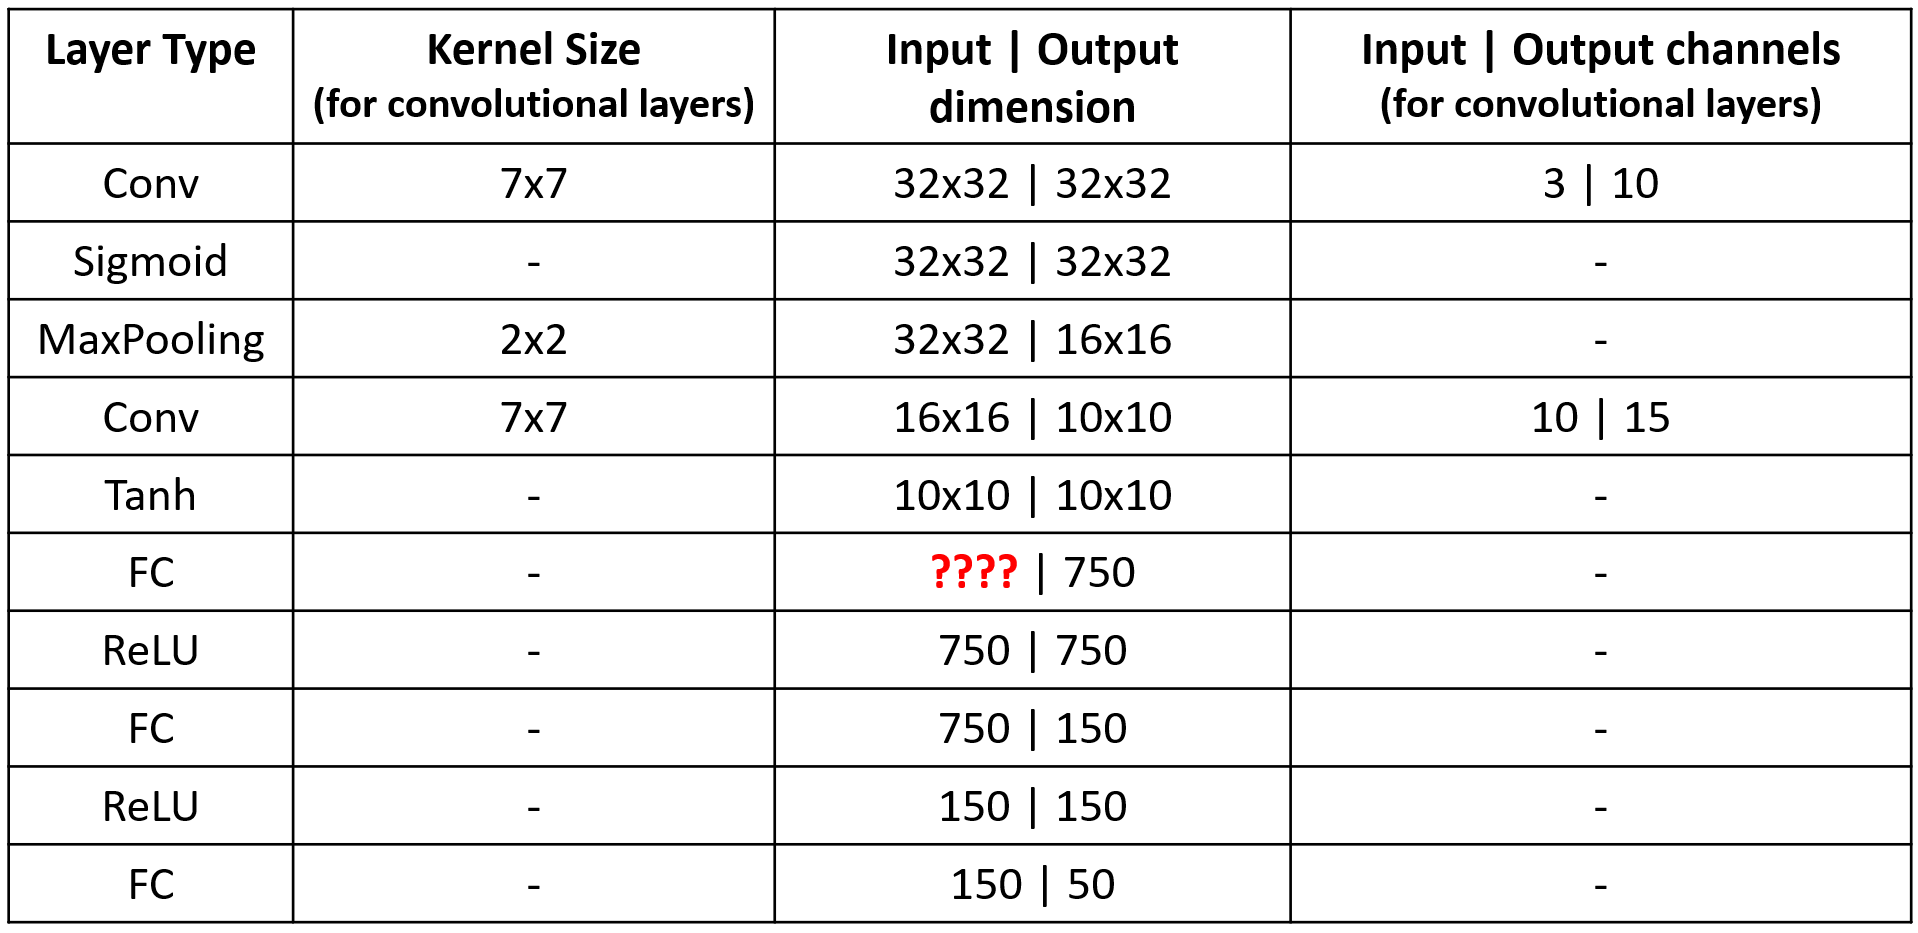



*   **Primera Capa convolucional**: filtro de 7x7 por 3 canales de entrada más el bias = 7x7x3 + 1 = 148 por 10 canales de salida = 1480 parámetros.
*   **Segunda Capa convolucional**: filtro de 7x7 por 10 canales de entrada más el bias =  491 por 15 canales de salida = 7365.
*   **Primera capa FC**: 1500 de tamaño de datos de entrada por 750 de salida = 1125000 más 750 de bias = 1125750.
*   **Segunda capa FC**: 750 de tamaño de datos de entrada por 150 de salida = 112500 más 150 de bias = 112650.
*   **Tercera capa FC**: 150 de tamaño de datos de entrada por 50 de salida = 7500 más 50 de bias = 7550.

**TOTAL** = CC1 + CC2 + CFC1 + CFC2 + CFC3 = 1480 + 7365 + 1125750 + 112650 + 7550 = **1254795 parámetros**.



**<h1>Selección de función de pérdida.</h1>**
Tras haber visto la documentación de pytorch así como otros artículos relacionados con la función de pérdida, parece haber un consenso general en que en tareas de clasificación multiclase ( que no multilabel ) se usa **CrossEntropy** en alguna de sus variantes. Como hemos comentado antes, no agregamos la capa de función **Softmax** al final porque esta función de pérdida ya aplica esta función a las salidas de nuestra red. Después, aplica Negative Likelihood ( NLLLoss ) que es otra función de pérdida. CrossEntropy es la siguiente fórmula:
$$
\ell(x, y) = L = \{l_1, \dots, l_N\}^\top, \quad
l_n = - \sum_{c=1}^{C} w_c \, y_{n,c} \log \frac{e^{x_{n,c}}}{\sum_{i=1}^{C} e^{x_{n,i}}}
$$

donde:


*   **x** es el input de la función de pérdida, es decir, la salida de la red.
*   **y** es el target.
*   **N** es la dimensión del batch.
*   **C** es el número de clases.
*   **$w_c$** es el peso de la clase c.
*   **$y_{n,c}$** es la etiqueta del ejemplo n del batch para la clase c.
*   **$x_{n,c}$** es la predicción de la red del ejemplo n del batch para la clase c.

Por último dependiendo del parámetro **reduction** el valor aportado es uno u otro. En nuestro caso lo dejamos por defecto y se calcula la media es decir:
$$
\sum_{n=1}^{N}\frac{l_n}{N}
$$

Una vez explicada como funciona **CrossEntropy**, escogemos como función de pérdida su versión flat, es decir, **CrossEntropyFlat**. Esta función es en esencia la misma solo que aplana la entrada y el target. Se escoge esta función no sólo porque es la variante de CrossEntropy destacada en la documentación de loss functions en fastai sino por comodidad en cuanto a operar con tensores, ya que podemos tener tensores de más de dos dimensiones y si no aplicamos flat, podría fallar. En la documentación de fastai encontramos el siguiente ejemplo:  


output = torch.randn(32, 5, 10)
target = torch.randint(0, 10, (32,5))

En este caso output tenemos 32 de batch_size con 5 ejemplos por cada y 10 clases. Con target tenemos un tensor de tamaño 32x5 de entre 0 y 9. Entonces tenemos  **output -> (32,5,10)** y **target -> (32,5)** lo que fallaría para CrossEntropy ya que tenemos un tensor de 3 dimensiones. En cambio, si aplanamos tenemos que **output -> (160,10)** y **target -> (160)** lo cual es correcto. En nuestra red, la salida ya está aplanada pero no está de más utilizar la versión flat para mayor seguridad.

**<h1>Selección de métricas.</h1>**
Finalmente, tenemos que seleccionar las métricas a monitorizar. Al ser un problema de clasificación se escogen las siguientes:
Las métricas que vamos a utilizar son las siguientes:

  - **accuracy**:  mide simplemente las predicciones acertadas.

  
$$
\text{accuracy} = \frac{\text{entradas clasificadas correctamente}}{\text{Total de entradas}}
$$

  - **precision**: indica el porcentaje de instancias clasificadas dentro de una clase que realmente pertenecen a una clase. Después calcula el promedio de esta métrica para cada clase y devuelve el valor.

$$
\text{precision} = \frac{\text{Verdaderos Positivos}}{\text{ Verdaderos Positivos + Falsos Positivos}}
$$

  - **recall**: indica la proporción de verdaderos positivos.

$$
\text{recall} = \frac{\text{Verdaderos Positivos}}{\text{ Verdaderos Positivos + Falsos Negativos}}
$$

  - **F1-score**: se trata de una combinación de precision y recall.

  $$
\text{f1score} = \frac{ 2 * \text{recall * precision}}{\text{ recall + precision}}
$$

De estas nos quedamos con accuracy y F1Score, que es lo que se pide evaluar, pero es conveniente definir tanto recall como precision para entender F1Score.

Pasamos ahora a construir el learner con **basenet**, con **SGD** con momentum 0.9, **lr = 0.01**.

In [ ]:

from torch.optim import SGD
from functools import partial

# Construimos el optimizador usando partial, seleccionando
# SGD con momentum 0.9
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)

# Constuimos el learner con conjunto de entrenamiento
# dls, modelo BaseNet, funcion de perdida CrossEntropy,
# el optimizador SGD y las metricas que se piden que son
# accuracy y F1 en su version macro
learn=Learner(dls, BaseNet, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )


In [ ]:
learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 10 x 32 x 32  
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     128 x 10 x 16 x 16  
MaxPool2d                                                      
____________________________________________________________________________
                     128 x 15 x 10 x 10  
Conv2d                                    7365       True      
Tanh                                                           
____________________________________________________________________________
                     128 x 1500          
Flatten                                                        
____________________________________________________________________________
                     128 x 750  

Como podemos comprobar, el número de parámetros coincide tanto por capa como en total con respecto a lo calculado anteriormente.

Ahora entrenamos el modelo.

**NOTA: Se nos pide en el último punto visualizar las métricas con plot_metrics. Por alguna razón, si sigo el orden establecido por el enunciado, da error al ejecutar plot_metrics, es por esto que mostramos justo después del entrenamiento las métricas**.

Ahora procedemos con el entrenamiento. Para ello tenemos que definir antes el vector de callbacks **cbs** indicando EarlyStopping, monitorizando la pérdida en validación y paciencia 5. Procedemos a entrenar con **25 épocas** y con **lr = 0.01**.

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.913126,3.911692,0.022400,0.000876,00:26
1,3.909312,3.905066,0.033200,0.006388,00:18
2,3.691927,3.573867,0.058400,0.023547,00:20
3,3.484501,3.402257,0.102000,0.057488,00:18
4,3.285234,3.265538,0.131200,0.088591,00:19
5,3.162185,3.123443,0.166000,0.133114,00:20
6,3.070208,3.057038,0.182000,0.151817,00:18
7,3.001279,2.949733,0.204800,0.169613,00:18
8,2.904113,2.889562,0.213200,0.186123,00:19
9,2.840547,2.811364,0.238000,0.212393,00:18


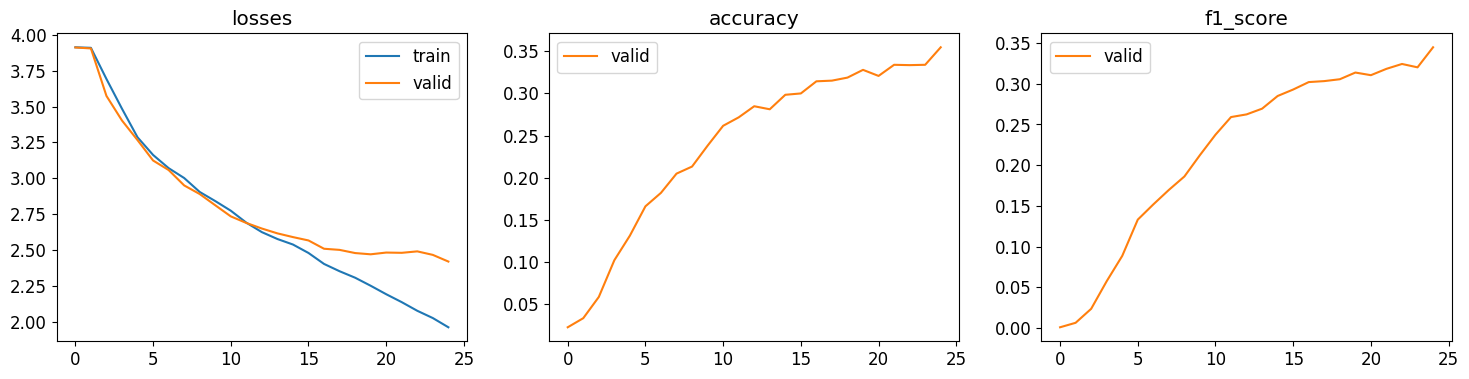

In [ ]:
# A CUBRIR POR EL ALUMNADO
# EarlyStopping con 5 de paciencia
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
n_epochs = 25

# Entrenamos con 25 epocas y lr = 0.01
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)
learn.recorder.plot_metrics()

Tras haber entrenado la red podemos observar varias cosas:


*   Las métricas de accuracy y f1_score muestran resultados bastante malos, en torno al 33-35%.
*   Se consumen las 25 etapas lo cual es coherente porque hemos introducido un early stopping con 5 de paciencia monitorizando "valid_loss" y como vemos no hay 5 etapas consecutivas sin mejora.
*   Cabe destacar el tiempo de entrenamiento de entorno 8 minutos.
*   Las métricas de accuracy y F1 por lo general crecen con el número de épocas, con alguna pequeña caída pero eventualmente vuelven a crecer.
*   Lo más destacable es visualizar la diferencia de las gráficas de **loss_function** y **valid_loss**, donde a partir de la décima época vemos como se empiezan a despegar, donde en entrenamiento la pérdida sigue el curso de bajada y en validación empieza a aplanarse e incluso subir. Eso indica un claro **sobreajuste**, es decir, el modelo empieza a aprender específicamente los datos de entrenamiento lo que hace que los datos de validación ( los no vistos ) sufran una pérdida en cuanto a predicción

Vamos ahora a predecir en el conjunto de test.

In [ ]:
test_dl = learn.dls.test_dl(files_test,with_labels=True, device='cuda')
preds, targs = learn.get_preds(dl=test_dl)

Vamos ahora a mostrar las métricas y herramientas que ilustran el comportamiento de la red.
**<h1>Matriz de confusión y diferencias en accuracy en train/validation/test</h1>**

La matriz de confusión es una matriz que tanto en cada fila como columna representa una de las posibles clases. El número que aparece en la fila **i** y columna **j** es el número de elementos de la clase **i** que se han clasificado ( erróneamente si i $\neq$ j, correctamente si i = j) en la clase **j**. Por tanto los aciertos están en la diagonal. Esto es muy útil para calcular la accuracy pues es la suma de las diagonales entre la suma total.

Number of train examples: 22500


Train Accuracy
50.080000000000005


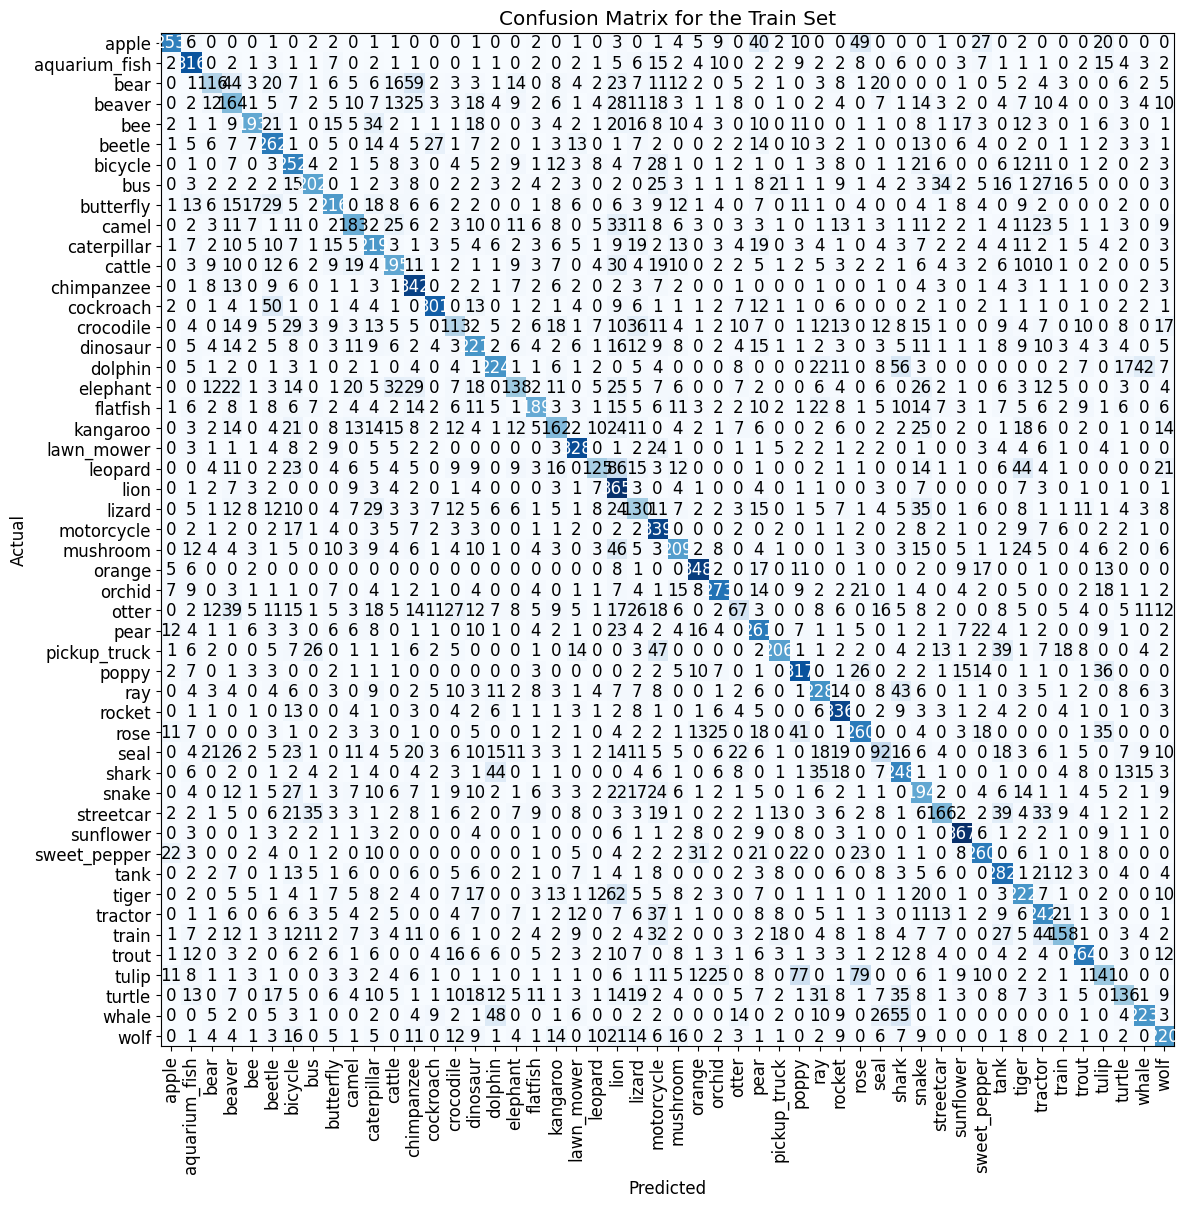

In [ ]:
# Matriz confusión train
interp = ClassificationInterpretation.from_learner(learn, 0)
cm = interp.confusion_matrix()
print('Number of train examples:', np.sum(cm))
interp.plot_confusion_matrix(figsize=(12, 12),title='Confusion Matrix for the Train Set')
print('Train Accuracy')
print(np.sum(np.diagonal(cm))/np.sum(cm)*100)

El gráfico no es muy ilustrativo al tener demasiada información concentrada en un espacio tan pequeño. No obstante vemos que la accuracy es muy pobre en el conjunto de entrenamiento aunque mejora con respecto a validación ( esto es normal porque la red ajusta los parámetros al conjunto de entrenamiento ). Para intentar sacar algo más de información, voy a intentar mostrar las 5 parejas de tuplas con más fallos.

In [ ]:
# Calculamos la lista de tuplas de la matriz menos diagonal
# Accedemos a las labels mediante dls.vocab
labels = dls.vocab
errores = [(labels[i],labels[j], cm[i,j]) for i in range(cm.shape[0])
                                       for j in range(cm.shape[1]) if i != j]

# Ordenamos de mayor a menor valor, es decir, más errores
errores_ord= sorted(errores, key=lambda x: x[2], reverse=True)

# Mostrar las 5 parejas con más errores
print(errores_ord[:5])

[('leopard', 'lion', np.int64(86)), ('tulip', 'rose', np.int64(79)), ('tulip', 'poppy', np.int64(77)), ('tiger', 'lion', np.int64(62)), ('bear', 'chimpanzee', np.int64(59))]


Como podemos comprobar, por ejemplo hay 86 leopardos clasificados como leones. Estas predicciones aunque sean erróneas, tienen sentido ya que elementos parecidos de clases distintas se clasifican en clases que pertenecen a la misma superclase. También se puede ver con las flores.

Number of validation examples: 2500


valid Accuracy
35.480000000000004


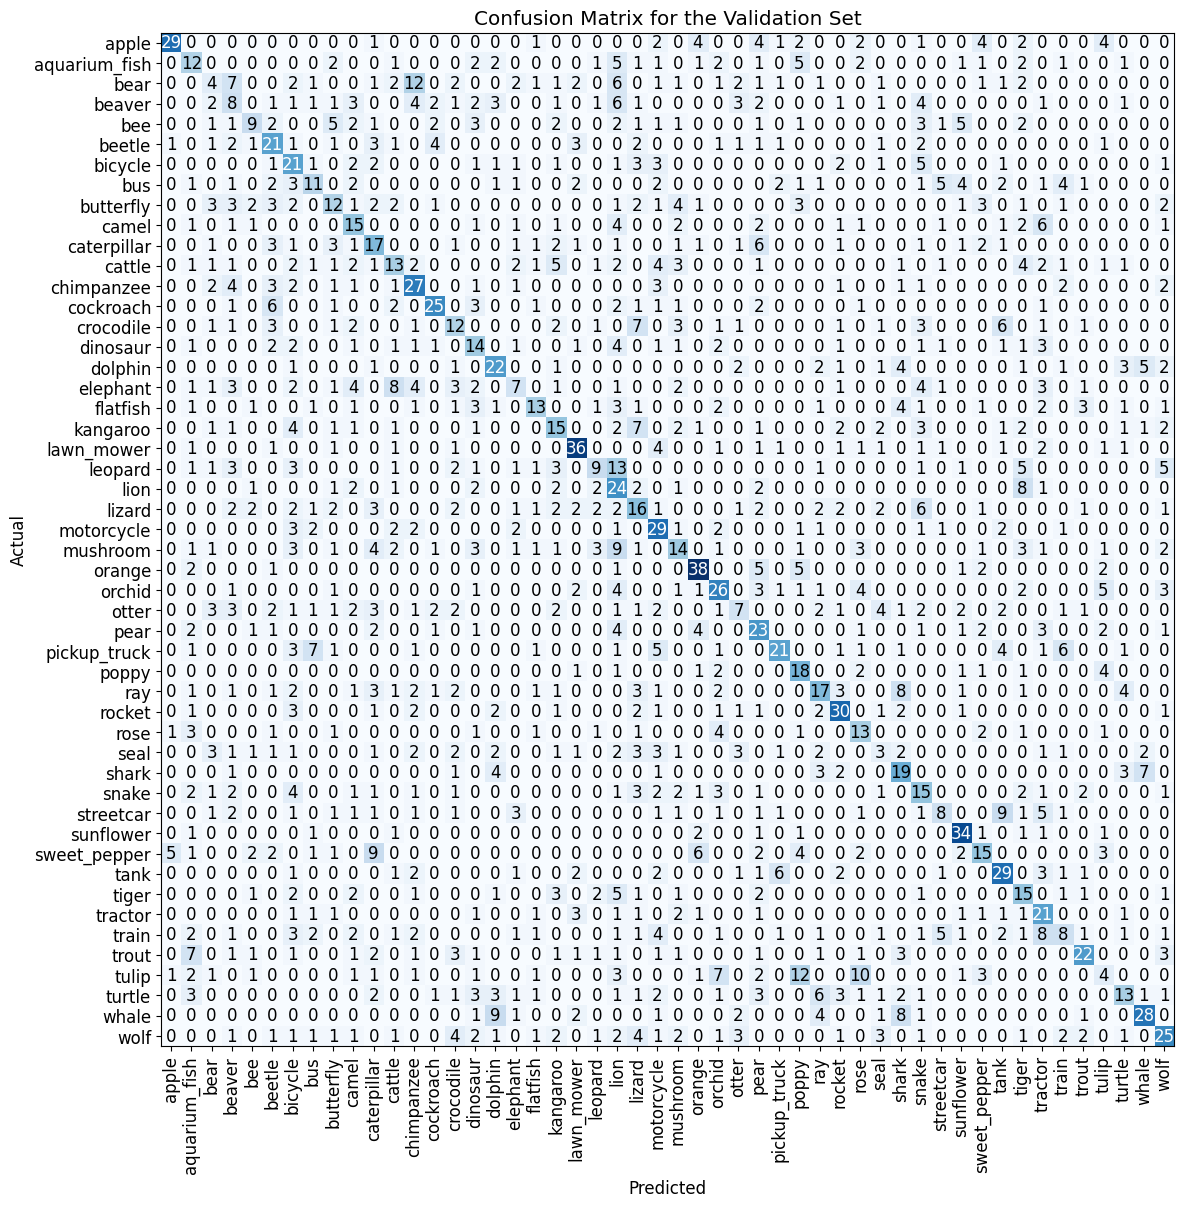

In [ ]:
# Matriz confusión valid
interp = ClassificationInterpretation.from_learner(learn, 1)
cm = interp.confusion_matrix()
print('Number of validation examples:', np.sum(cm))
interp.plot_confusion_matrix(figsize=(12, 12),title='Confusion Matrix for the Validation Set')
print('valid Accuracy')
print(np.sum(np.diagonal(cm))/np.sum(cm)*100)

Como se puede observar, la accuracy es la misma que en el valor de la última época de entrenamiento. Además vemos la caída de accuracy con respecto a entrenamiento. Ahora vamos a ver los errores más comunes en validación.

In [ ]:
# Calculamos la lista de tuplas de la matriz menos diagonal
# Accedemos a las labels mediante dls.vocab
labels = dls.vocab
errores = [(labels[i],labels[j], cm[i,j]) for i in range(cm.shape[0])
                                       for j in range(cm.shape[1]) if i != j]

# Ordenamos de mayor a menor valor, es decir, más errores
errores_ord= sorted(errores, key=lambda x: x[2], reverse=True)

# Mostrar las 5 parejas con más errores
print(errores_ord[:5])

[('leopard', 'lion', np.int64(13)), ('bear', 'chimpanzee', np.int64(12)), ('tulip', 'poppy', np.int64(12)), ('tulip', 'rose', np.int64(10)), ('mushroom', 'lion', np.int64(9))]


Volvemos a ver cosas similares al caso anterior, leopardo y leon que pertenecen a la misma superclase pero no a la misma clase, hay ejemplares de leopardo clasificados como leonae. Del mismo modo sucede con orquídeas y tulipanes.

Number of test examples: 5000


test Accuracy
34.9


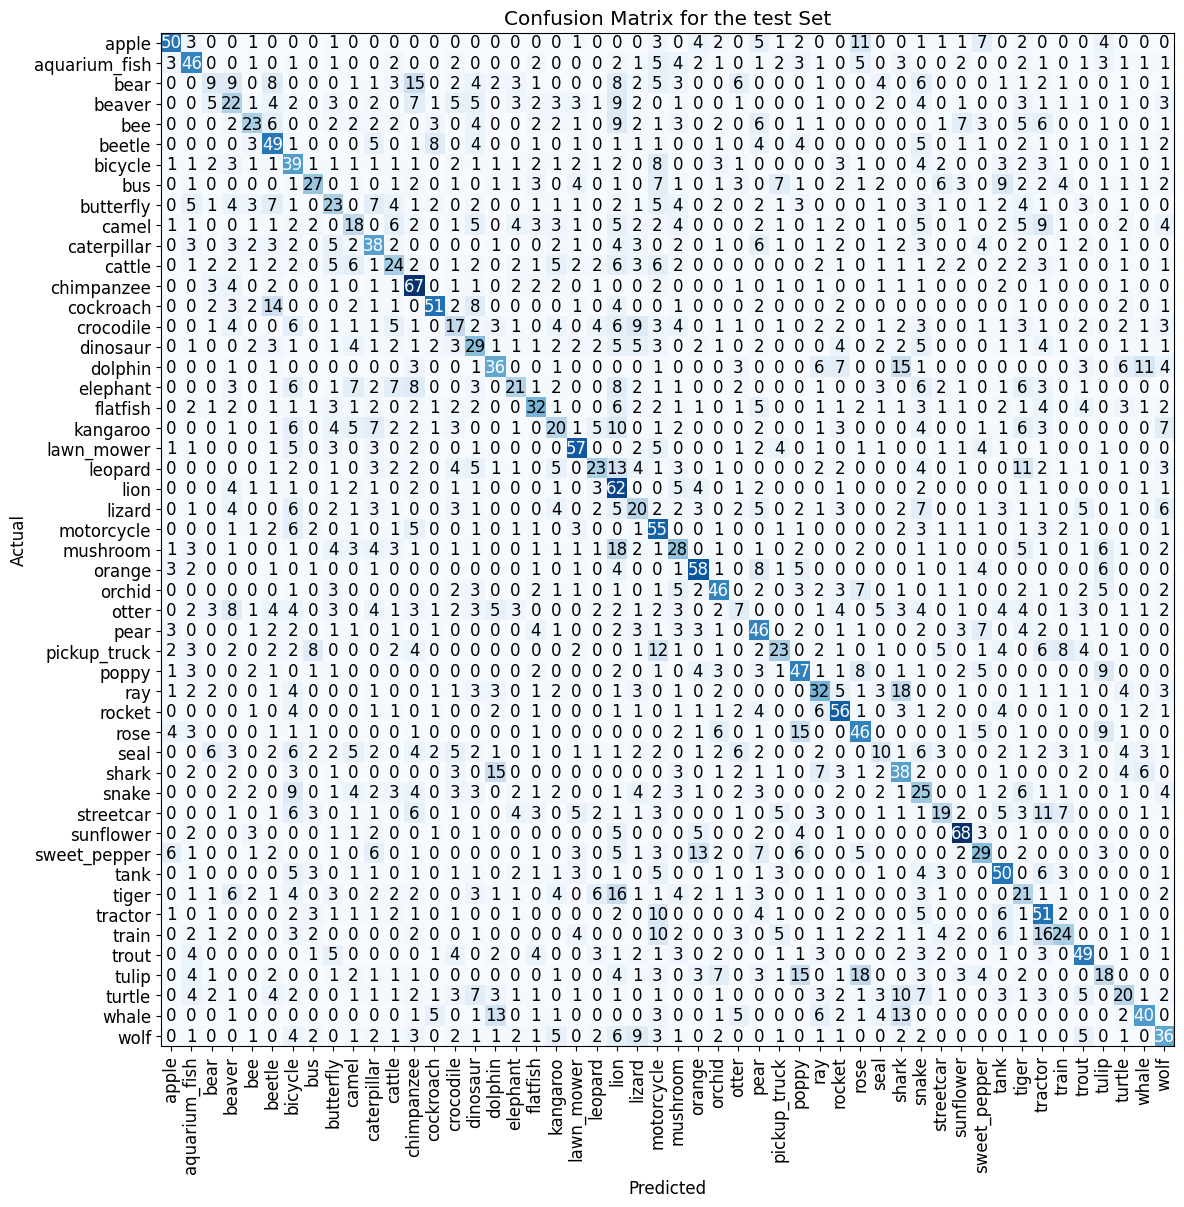

In [ ]:
# Matriz confusión test
interp = ClassificationInterpretation.from_learner(learn, 2, test_dl)
cm = interp.confusion_matrix()
print('Number of test examples:', np.sum(cm))
interp.plot_confusion_matrix(figsize=(12, 12),title='Confusion Matrix for the test Set')
print('test Accuracy')
print(np.sum(np.diagonal(cm))/np.sum(cm)*100)

Del mismo modo que antes, tenemos un accuracy muy pobre. Destaca que es muy similar al de validación y esto tiene sentido porque los pesos se ajustan en base al entrenamiento.

In [ ]:
# Calculamos la lista de tuplas de la matriz menos diagonal
labels = dls.vocab
errores = [(labels[i],labels[j], cm[i,j]) for i in range(cm.shape[0])
                                       for j in range(cm.shape[1]) if i != j]

# Ordenamos de mayor a menor valor, es decir, más errores
errores_ord= sorted(errores, key=lambda x: x[2], reverse=True)

# Mostrar las 5 parejas con más errores
print(errores_ord[:5])

[('mushroom', 'lion', np.int64(18)), ('ray', 'shark', np.int64(18)), ('tulip', 'rose', np.int64(18)), ('tiger', 'lion', np.int64(16)), ('train', 'tractor', np.int64(16))]


De nuevo, volvemos a ver que se clasifica erróneamente elementos de una clase en otra clase donde ambas pertenecen a la misma superclase.

En resumen, en cuanto a accuracy tenemos que:
$$
validation ≃ 35\%
$$
vs
$$
train ≃ 50\%
$$
vs
$$
 test ≃ 35\%
$$

## <font color='blue'> Comparando GPU y CPU (0.5 puntos)

<font color='blue'>Ahora el alumnado debe entrenar el mismo modelo, pero con CPU (`Entorno de Ejecución - Cambiar tipo de entorno de ejecución - CPU`). ¿Qué ocurre? ¿Hay alguna diferencia en cuanto al entrenamiento? ¿Qué ocurre si empleamos un batch size de tamaño $1$ o $256$ en CPU o GPU?

<font color='blue'>**Nota1**: no hay forma programática de ir cambiando de entorno de ejecución dentro de un bucle. De modo que es necesario modificarlo manualmente en `Entorno de ejecución`.

<font color='blue'>**Nota2**: no se trata de realizar un estudio exhaustivo ni de repetir el ejercicio al completo con distintos entornos de ejecución (CPU, GPU A100, GPU L4, GPU T4, TPU v6e-1, TPU v5e-1), aunque, quien quiera, es libre de hacerlo. Se trata solamente de documentar algunos breves experimentos (por ejemplo, empleando menos épocas), e intentar explicar los resultados obtenidos a nivel de tiempos de entrenamiento, y cómo en dichos tiempos influye el tamaño del batch y el entorno hardware en que se entrena.



Vamos a realizar una serie de experimentos que ilustren el tiempo de ejecución.


*   Entrenar con CPU solo durante 3 épocas. Como hemos visto nuestro learner tardaba unos 20 segundos por época. No vamos a entrenar 25 épocas porque el tiempo de ejecución se dispararía.
*   Entrenar con CPU y GPU  usando bs = 1 y bs = 256 durante 3 épocas para ver como afecta cambiar el tamaño del batch.
**NOTA: En estos experimentos se usa GPU T4 pero NO con acelerador por RAM.**

**<h1>Entrenamiento solo con CPU </h1>**



In [ ]:
# Medimos el tiempo de la celda
%%time
n_epochs = 3
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.912941,3.912087,0.019600,0.001044,00:44
1,3.908541,3.905056,0.026800,0.006495,00:41
2,3.666499,3.578010,0.066800,0.022803,00:40


CPU times: user 1min 12s, sys: 4.53 s, total: 1min 17s
Wall time: 2min 7s


**<h1>Entrenamiento GPU bs=1 </h1>**

In [ ]:
# Medimos el tiempo de la celda
n_epochs = 3
dls_bs1 = CIFAR_50.dataloaders(path/'train', bs=1)
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls_bs1, BaseNet, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 1 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     1 x 10 x 32 x 32    
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     1 x 10 x 16 x 16    
MaxPool2d                                                      
____________________________________________________________________________
                     1 x 15 x 10 x 10    
Conv2d                                    7365       True      
Tanh                                                           
____________________________________________________________________________
                     1 x 1500            
Flatten                                                        
____________________________________________________________________________
                     1 x 750      

In [ ]:
%%time
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.354150,3.211936,0.134400,0.104985,02:53
1,2.871701,3.000594,0.196400,0.164445,02:50
2,3.129386,2.955435,0.213200,0.191240,02:47


CPU times: user 6min 43s, sys: 26 s, total: 7min 9s
Wall time: 8min 31s


**<h1>Entrenamiento CPU bs=1 </h1>**

In [ ]:
n_epochs = 3
dls_bs1 = CIFAR_50.dataloaders(path/'train', bs=1)
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls_bs1, BaseNet, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 1 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     1 x 10 x 32 x 32    
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     1 x 10 x 16 x 16    
MaxPool2d                                                      
____________________________________________________________________________
                     1 x 15 x 10 x 10    
Conv2d                                    7365       True      
Tanh                                                           
____________________________________________________________________________
                     1 x 1500            
Flatten                                                        
____________________________________________________________________________
                     1 x 750      

In [ ]:
%%time
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.224518,3.174047,0.163200,0.136703,06:01
1,2.993795,3.073778,0.178000,0.147472,06:17
2,2.663569,3.029220,0.183600,0.163404,06:16


CPU times: user 15min 54s, sys: 34.4 s, total: 16min 29s
Wall time: 18min 36s


**<h1>Entrenamiento GPU bs=256 </h1>**

In [ ]:

n_epochs = 3
dls_bs256 = CIFAR_50.dataloaders(path/'train', bs=256)
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls_bs256, BaseNet, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 256 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     256 x 10 x 32 x 32  
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     256 x 10 x 16 x 16  
MaxPool2d                                                      
____________________________________________________________________________
                     256 x 15 x 10 x 10  
Conv2d                                    7365       True      
Tanh                                                           
____________________________________________________________________________
                     256 x 1500          
Flatten                                                        
____________________________________________________________________________
                     256 x 750  

In [ ]:
%%time
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,2.750367,2.802212,0.240400,0.220968,00:20
1,2.685037,2.749440,0.258400,0.238602,00:19
2,2.634958,2.720915,0.263200,0.245846,00:21


CPU times: user 3.39 s, sys: 657 ms, total: 4.04 s
Wall time: 1min 1s


**<h1>Entrenamiento CPU bs=256 </h1>**

In [ ]:
n_epochs = 3
dls_bs256 = CIFAR_50.dataloaders(path/'train', bs=256)
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls_bs256, BaseNet, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 256 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     256 x 10 x 32 x 32  
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     256 x 10 x 16 x 16  
MaxPool2d                                                      
____________________________________________________________________________
                     256 x 15 x 10 x 10  
Conv2d                                    7365       True      
Tanh                                                           
____________________________________________________________________________
                     256 x 1500          
Flatten                                                        
____________________________________________________________________________
                     256 x 750  

In [ ]:
%%time
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,2.686912,2.833974,0.232000,0.217425,00:37
1,2.602484,2.785042,0.242400,0.227343,00:40
2,2.559320,2.757057,0.250000,0.233534,00:38


CPU times: user 1min 7s, sys: 4.17 s, total: 1min 11s
Wall time: 1min 56s


**<h1>Resultados</h1>**

$$
\begin{array}{|c|c|c|}
\hline
\text{} & \text{CPU} & \text{GPU T4} \\
\hline
\text{bs = 1} & \text{6mins 15s / época} & \text{2mins 50s / época} \\
\hline
\text{bs = 128} & \text{42s / época} & \text{20s / época} \\
\hline
\text{bs = 256} & \text{38s / época} & \text{20s / época} \\
\hline
\end{array}
$$

Observaciones:


*   Por lo que se puede observar, en general la CPU es bastante más lenta que la GPU, que en nuestro caso es aproximadamente el doble de lenta. Aún así, por experiencias previas, esperaba que fuera más lenta todavía. Esto se puede deber a que no es una red muy grande y que el tamaño de las imágenes es 32x32 lo cuál es medianamente pequeño y por tanto no estemos aprovechando tanto los beneficios de la GPU.
*   A medida que aumenta el tamaño del batch, parece ser que las ejecuciones son más rápidas. Esto tiene sentido pues a menor batch_size, mayor cantidad de batches hay y por tanto más número de actualizaciones de pesos y por tanto el entrenamiento es más lento.
*   Sorprende que para bs=128 y bs = 256 es bastante similar en cuánto a tiempo de ejecución pero tampoco es un cambio tan grande ( es el doble ) como lo es bs = 1 en comparación con bs = 128 ( 128 veces ).


## <font color='blue'> Eliminando FC layers (0.5 puntos)

<font color='blue'>Sabemos que el hecho de tener FC layers en una red convolucional fuerza a la entrada a tener un determinado tamaño. Del mismo modo, sabemos que las FC layers concentran buena parte de los pesos de una red. ¿De qué modo podríamos eliminarlas de nuestra arquitectura?  En este apartado debe implementar BaseNet pero sin utilizar FC layers. ¿Cuántos pesos tiene el nuevo modelo? Entrene el nuevo modelo siguiendo el mismo protocolo de entrenamiento, con los mismos hiperparámetros, del primer apartado. ¿Qué rendimiento se obtiene ahora? ¿Por qué?

Para eliminar completamente las FC layers, tenemos que tener en cuenta que necesitamos generar 50 datos de salida para que el modelo realiza la clasificación en las 50 clases utilizando softmax. Con las capas FC bastaba con que la última capa tuviera 50 características de salida. En nuestro caso, vamos a utilizar **Adaptive pooling**, que reduce los datos de tamaño **(bs, C, H, W)** a **(bs, C, Tam_x, Tam_y)** de forma automática, donde (Tam_x, Tam_y) se le pasa como parámetro a la capa de pooling. En nuestro caso le pasamos como parámetro 1, para obtener unos datos de tamaño (bs, n_clases, 1, 1). Para que esta capa reciba como entrada las n_clases, necesitamos que la última capa convolucional tenga  **out_channels = 50.** Por último, usamos **Flatten()** para aplanar los datos a un vector de tamaño (bs, n_clases), para realizar la predicción.

In [ ]:
from torch.optim import SGD
from functools import partial
# A CUBRIR POR EL ALUMNADO

BaseNetNoFC = sequential(
    nn.Conv2d(in_channels=3, out_channels=10, kernel_size=7, padding=3),
    nn.Sigmoid(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=10, out_channels=50, kernel_size=7, padding=0),
    nn.Tanh(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten()
)

SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls, BaseNetNoFC, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )

learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 10 x 32 x 32  
Conv2d                                    1480       True      
Sigmoid                                                        
____________________________________________________________________________
                     128 x 10 x 16 x 16  
MaxPool2d                                                      
____________________________________________________________________________
                     128 x 50 x 10 x 10  
Conv2d                                    24550      True      
Tanh                                                           
____________________________________________________________________________
                     128 x 50 x 1 x 1    
AdaptiveAvgPool2d                                              
____________________________________________________________________________
                     128 x 50   

Como vemos, tenemos **26030** parámetros frente a los **1,254,795** del modelo FC. Esto coincide totalmente con la idea de que en las capas FC se concentran la mayoría de parámetros, que, como vimos en el cálculo manual de los parámetros en el ejercicio anterior, es cierto. Vamos ahora a entrenar el modelo con los mismos hiperparámetros que en el apartado anterior.

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.899702,3.879325,0.044400,0.012671,00:04
1,3.752859,3.708123,0.078000,0.037378,00:05
2,3.666939,3.660511,0.083200,0.044057,00:04
3,3.636626,3.637991,0.098800,0.062432,00:04
4,3.620824,3.625218,0.086000,0.053017,00:04
5,3.601959,3.604757,0.089200,0.051722,00:04
6,3.591134,3.593884,0.089600,0.058092,00:04
7,3.577057,3.579192,0.102400,0.064518,00:04
8,3.563286,3.566887,0.105200,0.072878,00:04
9,3.547768,3.560637,0.101200,0.068844,00:04


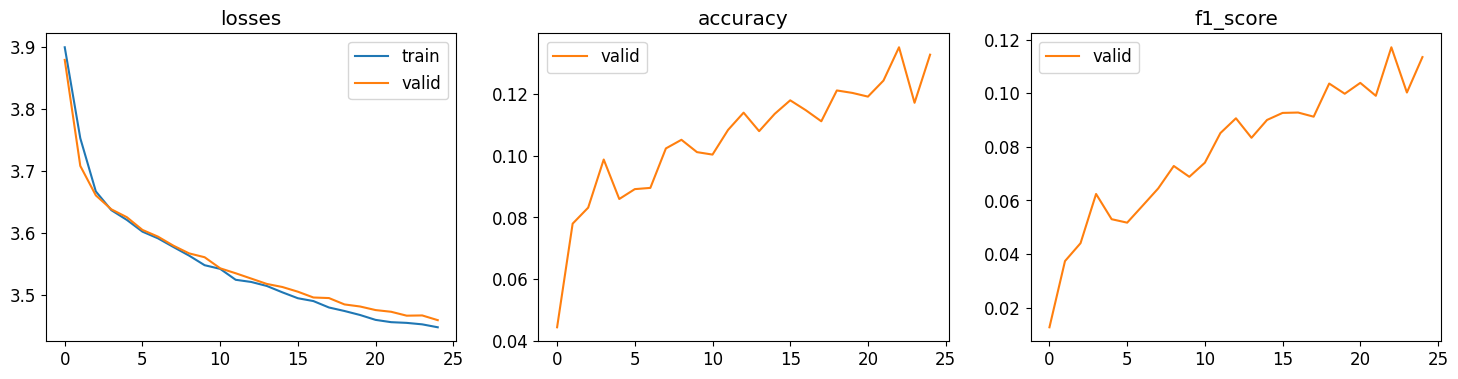

In [ ]:
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
n_epochs = 25
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)
learn.recorder.plot_metrics()

Observaciones:
*   El modelo es bastante peor. Esto es posible que se deba a que el número de parámetros quitando FC layers es más de 40 veces menos que en basenet original. Esto puede indicar también que la mayoría de características de nuestro modelo eran aprendidas a través de las capas FC, por lo que para mejorar el modelo quizá convendría aumentar el número de capas convolucionales y/o número de canales de las mismas, para que estas capas sean la que extraigan características, que son para lo que originalmente están pensadas.
*   Podemos ver que no hay sobreajuste, a diferencia del ejercicio anterior. Esto coincide con la teoría donde se nos dice que a mayor número de parámetros, es más fácil que haya sobreajuste.

# <font color='blue'> **Ejercicio 2:** **Mejoras sobre el modelo BaseNet (4 puntos)**
<font color='blue'>Ahora el objetivo es crear una versión mejorada del modelo _BaseNet_ (implementado en el primer apartado del ejercicio anterior). Para ello, se puede experimentar con distintas funciones de activación, funciones de pérdida, una mayor o menor profundidad de la red, un mayor o menor número de filtros por bloque convolucional, y/o diferentes técnicas de regularización u optimización, entre otras. De hecho, los alumnos deben sentirse libres para experimentar e incorporar todas las modificaciones que consideren pertinentes, incluyendo elementos no vistos ni en teoría ni en prácticas (por ejemplo, componentes que hayan podido descubrir a través de la revisión de artículos científicos) u otros más sencillos y directos (como entrenar por más épocas). **Se valorará la originalidad y complejidad de la propuesta realizada.**

<font color='blue'>Es necesario destacar que **es imprescindible justificar de la mejor forma posible las decisiones tomadas** (ya sea mediante evidencia empírica o mediante literatura científica), **así como el rendimiento obtenido** (esto es, intentar explicar qué es lo que hace que mejoren los resultados; desde este punto de vista, es importante moverse de la mera constatación al intento de explicación). También es importante remarcar que **las mejoras introducidas, dentro de lo posible, deben realizarse de forma incremental**, es decir, no basta con crear directamente (de forma "mágica") un único modelo y evaluarlo:  **es necesario justificar y describir qué pasos y resultados intermedios nos han llevado a diseñar ese modelo concreto**. Se debe describir cada una de las mejoras incorporadas, así como analizar los resultados obtenidos (del mismo modo que se hizo en el Ejercicio 1), y se debe emplear  un $10\%$ de los ejemplos de entrenamiento para validación. También es necesario, al igual que en el Ejercicio 1, desglosar el número de parámetros del modelo final, y se debe hacer un `summary()` del modelo para verificar que la arquitectura se ha construido correctamente y que el número de parámetros se corresponde con lo esperado.  

<font color='blue'>Como referencia para los estudiantes, se espera que la _accuracy_ en validación alcance, como mínimo, el $65\%$.


**NOTA: En cuanto al cálculo de parámetros, solo se va a realizar el del modelo final, si no habría que hacer un cálculo para cada incremento del modelo y sería repetir muchas veces lo mismo.**

En base a los experimentos realizados hemos sacado varias cosas en claro:
*   Hay que mejorar el entrenamiento ( ni si quiera la accuracy en train supera el 50% y en validación llega al 35% ).
*   Hay que corregir el sobreajuste.
*   El experimento anterior sugiere que son necesarias la inclusión de más capas convolucionales.

Antes que meternos en ciertos hiperparámetros vamos a pensar sobre la arquitectura de nuestro modelo. Como hemos visto, en nuestro caso necesitamos incluir capas convolucionales. Tras haber revisado el documento <href a="https://cs231n.github.io/convolutional-networks/">https://cs231n.github.io/convolutional-networks/</href>, se recomienda que la red tenga la siguiente estructura:

INPUT -> [[CONV -> RELU]*N -> POOL?]*M -> [FC -> RELU]*K -> FC

donde  N >= 0 ( y normalmente N <= 3), M >= 0, K >= 0 (y normalmente K < 3).

De aquí vemos varias cosas:

*   La función de activación más común suele ser la RELU.
*   Parece aconsejable introducir pooling después de cada bloque convolucional.

En cuanto a las funciones de activación, tras ver este documento surge la pregunta de ¿ Por qué se suele escoger RELU? ¿ Deberíamos cambiar nuestra sigmoide y tangente hiperbólica por RELU? Siguiendo las indicaciones de este articulo <href a="https://pmc.ncbi.nlm.nih.gov/articles/PMC9415767/">https://pmc.ncbi.nlm.nih.gov/articles/PMC9415767/</href>, además de lo que sabemos de teoría, sugieren que tanto la tangente hiperbólica como la sigmoide sufren de **vanishing gradient**. Por esto decidimos cambiar estas funciones por RELU.

Vamos a realizar el primer entrenamiento de nuestra red. Para ello vamos a seleccionar por ejemplo **N = 2, M = 2 y K = 0** en la fórmula presentada anteriormente. Se toman estos parámetros por dar más profundidad a la parte convolucional y para intentar reducir el overfitting que suelen dar las capas FC, además de intentar dejar a las convoluciones ser las que extraigan las características. Se van a dejar los mismos parámetros que en la red anterior. Estos los trataremos después. Nótese además que no hemos introducido elementos de regularización como tal, los cuáles nuestra red requería.
Las dos nuevas capas convolucionales se diseñan de la siguiente forma. Se introducen de forma que las salidas de las capas existentes sean las mismas que antes. Para esto es posible que tengamos que adaptar el padding en alguna de ellas.

In [ ]:
import torch.nn as nn
BaseNetImp = sequential(
    nn.Conv2d(in_channels=3, out_channels=10, kernel_size=7, padding=3),
    nn.ReLU(),
    nn.Conv2d(in_channels=10, out_channels=10, kernel_size=7, padding=3),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=10, out_channels=10, kernel_size=7, padding=3),
    nn.ReLU(),
    nn.Conv2d(in_channels=10, out_channels=15, kernel_size=7, padding=0),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(in_features=15*5*5, out_features=50)
)


Una vez definida la red, definimos el learn con las mismas características que el learn anterior pero con la nueva red.

In [ ]:
from torch.optim import SGD
from functools import partial
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls, BaseNetImp, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 10 x 32 x 32  
Conv2d                                    1480       True      
ReLU                                                           
Conv2d                                    4910       True      
ReLU                                                           
____________________________________________________________________________
                     128 x 10 x 16 x 16  
MaxPool2d                                                      
Conv2d                                    4910       True      
ReLU                                                           
____________________________________________________________________________
                     128 x 15 x 10 x 10  
Conv2d                                    7365       True      
ReLU                                                           
____________________________________

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.897433,3.880237,0.020800,0.002836,00:06
1,3.791448,3.724661,0.062000,0.027102,00:05
2,3.569458,3.499441,0.087200,0.048461,00:06
3,3.367950,3.338162,0.124800,0.099788,00:05
4,3.194185,3.169734,0.157200,0.133312,00:06
5,3.071283,3.053621,0.189200,0.170731,00:06
6,2.920289,2.961525,0.209600,0.193903,00:07
7,2.825535,2.892188,0.221200,0.204258,00:06
8,2.756804,2.831304,0.237600,0.228616,00:05
9,2.735144,2.828681,0.239600,0.230498,00:05


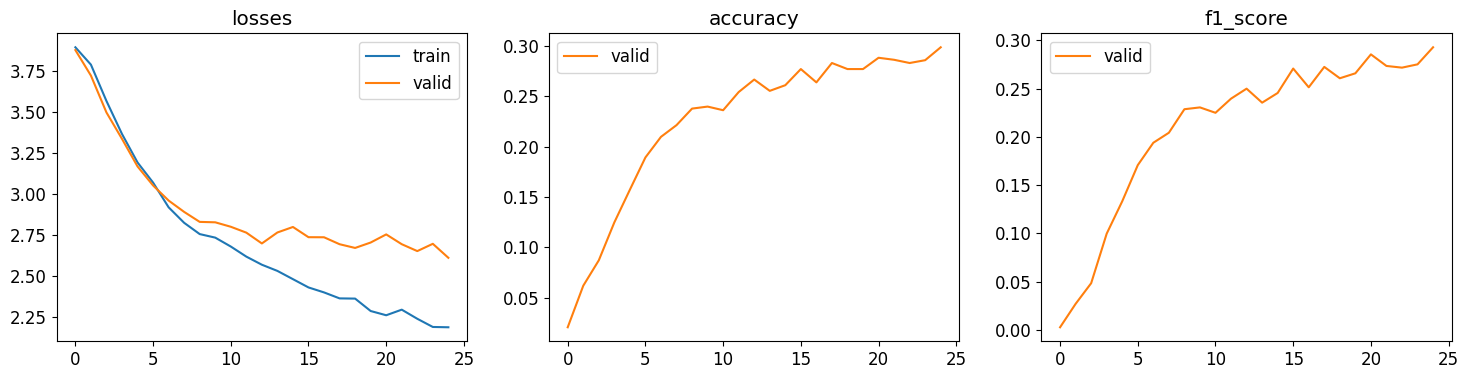

In [ ]:
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
n_epochs = 25
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)
learn.recorder.plot_metrics()

Tras este primer incremento podemos ver que este modelo es algo peor que el inicial. A pesar de eso se pueden sacar varias cosas en conclusión. Aunque podamos apreciar algo de sobreajuste es menos marcado que en basenet original. Esto se puede ver tanto en la gráfica donde vemos algo de generalization gap pero el conjunto de validación sigue bajando un poco y porque no ha saltado el callback de early stopping. Vamos ahora a revisar los hiperparámetros de cada capa, en especial el tamaño de kernel y los canales de entrada y salida.

En cuanto al tamaño de kernel, el primer artículo referenciado sugiere utilizar kernels de tamaños pequeños, es decir 3x3 o 5x5.

Además, hemos visto que el número de parámetros ( cerca de 37000 ) es muy pequeño, en comparación con basenet que en sí no es una red muy grande.

Para el número de canales, tenemos que tener en cuenta dos cosas:
1.    El patrón de crecimiento ( o decrecimiento ) de los filtros por capa.
2.    El número inicial de canales.

En cuanto al primer punto, el artículo https://arxiv.org/pdf/2104.13993, habla sobre la estructura de estos canales, donde dice que la distribución en pirámide ( por ejemplo empezar en 32, y duplicar este número en cada capa ) es la estructura tradicional, pero no tiene por qué ser la de mejor rendimiento. En nuestro caso, vamos a utilizar la distribución uniforme, que tiene una estructura de usar el mismo tamaño de filtros a lo largo de cada capa convolucional. Además, en el artículo menciona algunos resultados en nuestro dataset CIFAR-100 donde la distribución uniforme ofrecía buenos resultados.

En cuanto al número de canales, hemos visto que tenemos que aumentar el número de parámetros de la red. Vamos a empezar con 64 que supone un crecimiento sustancial en el número de canales.

In [ ]:
import torch.nn as nn
BaseNetImp = sequential(
    nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=0),
    nn.ReLU(),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=0),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=0),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Linear(in_features=64*6*6, out_features=50)
)

In [ ]:
from torch.optim import SGD
from functools import partial
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls, BaseNetImp, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 30 x 30  
Conv2d                                    1792       True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 28 x 28  
Conv2d                                    36928      True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 14 x 14  
MaxPool2d                                                      
Conv2d                                    36928      True      
ReLU                                                           
____________________________________________________________________________
                     128 x 64 x 12 x 12  
Conv2d                                    369

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.674085,3.461687,0.101600,0.058227,00:05
1,3.188486,3.112142,0.176000,0.147155,00:05
2,2.897758,2.829609,0.233200,0.207953,00:05
3,2.701295,2.682045,0.276800,0.253913,00:05
4,2.504565,2.551699,0.301200,0.281663,00:05
5,2.287516,2.415825,0.352000,0.337347,00:05
6,2.158731,2.324650,0.367600,0.355816,00:05
7,2.012673,2.308044,0.365200,0.357945,00:05
8,1.912440,2.305956,0.386400,0.372388,00:05
9,1.770515,2.266195,0.392000,0.385963,00:06


No improvement since epoch 9: early stopping


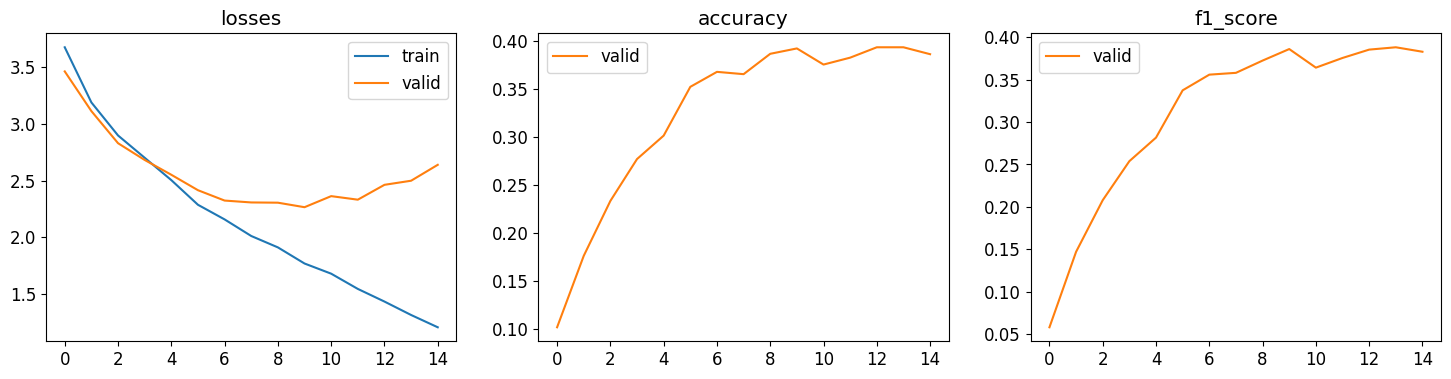

In [ ]:
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
n_epochs = 25
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs)
learn.recorder.plot_metrics()

Observaciones:
*   El rendimiento del modelo es mejor ya que basenet.
*   Sin embargo, vemos una gran cantidad de sobreajuste.

En este momento tenemos que plantear opciones de regularización. Para ello vamos a introducir los conceptos de Dropout, batch normalization y loss penalties.

El **dropout** consiste en eliminar aleatoriamente una parte de las neuronas de una capa. Esto promueve la regularización pues al eliminar ciertas neuronas, las otras tienen que adaptarse a la falta de ellas. Para las capas Conv, se usa dropout2d, que elimina canales enteros. Dropout recibe un parámetro **p** que indica la probabilidad de desactivar estas unidades. Para las capas FC, vimos en teoría que se recomienda entorno a 0.5. Para las capas conv, nos fijamos en el siguiente artículo https://arxiv.org/pdf/1904.03392 donde hace experimentos con p bastante bajos y nos quedamos con p = 0.2.

En cuanto a **batch_normalization**, su principal motivo es agilizar el entrenamiento por la normalización de los datos. En el artículo https://arxiv.org/pdf/1809.00846v1, podemos encontrar como BN induce un coeficiente de regularización, por lo que pese a que se indique que se usa para agilizar entrenamiento, también sirve para regularizar el modelo.

Se nos comentó en teoría que el sobreajuste se asocia con grandes pesos. Para esto a la función de pérdida se le puede añadir un término de regularización que suele consistir en un parámetro lambda por una operación sobre los pesos del modelo como el módulo o la potencia al cuadrado. Con esto  conseguimos asociar a la función de pérdida una penalización adicional por pesos altos. En nuestro caso vamos a utilizar una regularización parecida a **L2** que añade el término:

$$
λ\sum_{j=0}^{M}W_j^{2}
$$
a la función de pérdida. En nuestro caso vamos a usar **weight_decay** que es muy similar y en muchos casos igual a L2 como vimos en teoría. En nuestro caso exactamente no lo es pues estamos usando momentum. Necesitamos escoger un valor de wd. Para ello, el artículo https://arxiv.org/pdf/1803.09820 habla bastante sobre ello y es recomendable tomar valores muy bajos por lo que nos quedamos con $10^{-4}$ cuyo valor o parecidos son usados en el estudio como ejemplo.


In [ ]:
import torch.nn as nn
BaseNetImp = sequential(
    nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=0),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=0),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=0),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(in_features=64*6*6, out_features=50)
)

In [ ]:

from torch.optim import SGD
from functools import partial
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls, BaseNetImp, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 64 x 30 x 30  
Conv2d                                    1792       True      
BatchNorm2d                               128        True      
ReLU                                                           
Dropout2d                                                      
____________________________________________________________________________
                     128 x 64 x 28 x 28  
Conv2d                                    36928      True      
BatchNorm2d                               128        True      
ReLU                                                           
Dropout2d                                                      
____________________________________________________________________________
                     128 x 64 x 14 x 14  
MaxPool2d                                                      
Conv2d                              

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.271674,2.968525,0.201200,0.169480,00:07
1,3.076830,2.798490,0.246000,0.221578,00:07
2,2.976485,2.671711,0.276400,0.253528,00:07
3,2.916119,2.620955,0.272400,0.256336,00:07
4,2.831462,2.506122,0.308800,0.288697,00:07
5,2.753229,2.424967,0.334800,0.321058,00:07
6,2.698675,2.347739,0.353600,0.338070,00:07
7,2.662762,2.337416,0.351200,0.333580,00:07
8,2.632277,2.271559,0.376800,0.354884,00:07
9,2.575559,2.214128,0.382000,0.373675,00:08


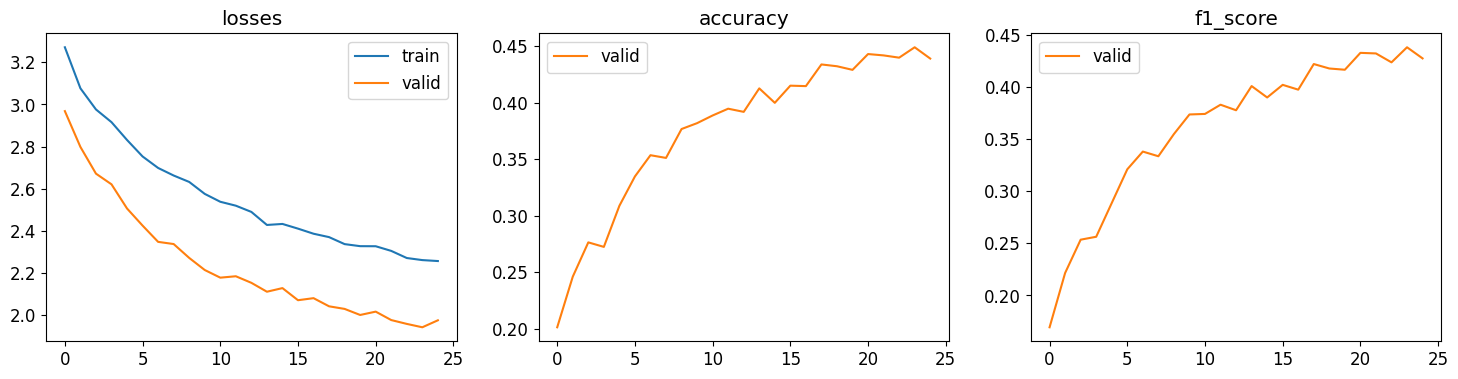

In [ ]:
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=5)]
n_epochs = 25
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs, wd=1e-4)
learn.recorder.plot_metrics()

Observaciones:
*   La accuracy en validación comienza a mejorar y nos acercamos al mínimo requerido de 65%.
*   Vemos por primera vez el fenómeno de que la pérdida en train es mayor que en validación ¿ Significa esto que el conjunto de validación es más fácil que entrenamiento ? No debería pues se ha seleccionado aleatoriamente, además de que los experimentos anteriores siempre hemos visto que por lo general loss en train es menor que en validación por lo que no parece que sea más fácil per se. La clave está en dropout, que se activa en train pero se desactiva en validación/test, luego sacrificamos accuracy por robustez y capacidad de generalización. Además, vemos que la diferencia es de unos 0.2 luego no es demasiado.
* En general parece que la regularización aplicada ha surtido efecto.

En el siguiente paso, tenemos  en cuenta que las funciones de pérdida continuan bajando, por lo que vamos a entrenar durante **50 épocas** y aumentar la paciencia. Además, vamos a intentar mejorar el accuracy haciendo los siguientes cambios:
*   Aumentar el número de canales a 128 para intentar aprender más características.
*   Normalizar los datos de entrada. Para esto usaremos Normalize() en el datablock.
*   Usar data augmentation. Esto se basa en introducir pequeñas transformaciones a los datos para tener más ejemplos.


In [ ]:
import torch.nn as nn
BaseNetImp = sequential(
    nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.Dropout2d(0.2),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(in_features=128*8*8, out_features=50),

)

In [ ]:
from torch.optim import SGD
from functools import partial
CIFAR_50 = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.1, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(32, method = 'squish')],
    batch_tfms=[*aug_transforms(), Normalize()]
)

dls = CIFAR_50.dataloaders(path/'train', bs=128)
SGD = partial(OptimWrapper, opt=SGD, momentum = 0.9)
learn=Learner(dls, BaseNetImp, loss_func=CrossEntropyLossFlat()
        , metrics=[accuracy, F1Score(average='macro')],
        opt_func=SGD
        )
learn.summary()

Sequential (Input shape: 128 x 3 x 32 x 32)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 128 x 32 x 32 
Conv2d                                    3584       True      
BatchNorm2d                               256        True      
ReLU                                                           
Dropout2d                                                      
Conv2d                                    147584     True      
BatchNorm2d                               256        True      
ReLU                                                           
Dropout2d                                                      
____________________________________________________________________________
                     128 x 128 x 16 x 16 
MaxPool2d                                                      
Conv2d                                    147584     True      
BatchNorm2d                               256        True      
ReLU                       

epoch,train_loss,valid_loss,accuracy,f1_score,time
0,3.229549,2.846274,0.228800,0.210788,00:10
1,2.908967,2.578929,0.286800,0.273106,00:10
2,2.734282,2.436643,0.322800,0.307930,00:10
3,2.600874,2.297171,0.366400,0.349447,00:10
4,2.515836,2.214857,0.382400,0.370144,00:10
5,2.422271,2.156785,0.396400,0.382191,00:10
6,2.383364,2.079896,0.418800,0.406929,00:10
7,2.323809,2.044065,0.424800,0.412819,00:10
8,2.257389,2.064553,0.431200,0.416185,00:10
9,2.220829,2.008096,0.433200,0.420019,00:10


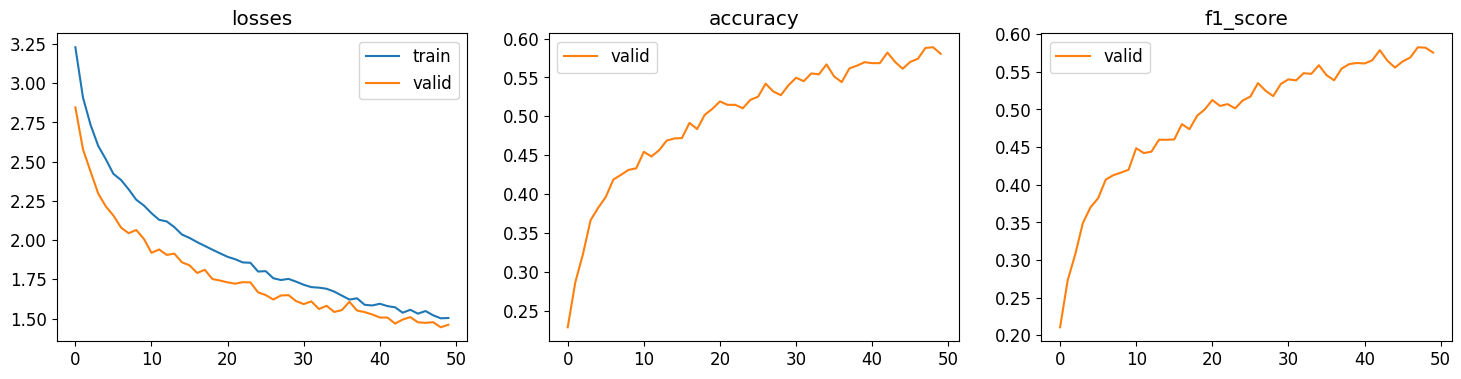

In [ ]:
cbs=[EarlyStoppingCallback(monitor='valid_loss', patience=10)]
n_epochs = 50
learn.fit(lr=0.01 ,n_epoch=n_epochs, cbs= cbs, wd=1e-4)
learn.recorder.plot_metrics()

**NOTA: He realizado más experimentos cambiando todo tipo de cosas y no he conseguido llegar al 65%. Como he pasado de el anterior experimento de 44% a 60% en accuracy parece que me he conformado por la cercanía al mínimo, pero realmente he hecho muchos experimentos más y no se que más puedo introducir. No he querido poner todos los experimentos porque no significaban una ganancia en accuracy y no quería saturar el notebook con experimentos fallidos. Aun así, creo que se ha hecho un buen trabajo de investigación,leyendo muchos artículos y apuntes de teoría con intención de mejorar el rendimiento, además de que se ha intentado justificar todos los cambios de la mejor manera.**

Observaciones:

*   Como vemos, nos hemos acercado bastante al 65% que se pedía en el ejercicio.
*   Con respecto al experimento anterior a este hemos visto como la diferencia entre train y valid se acercan mucho y ambas siguen teniendo una tendencia en bajada por lo que es posible que si se sigue entrenando por más épocas, podamos alcanzar una mejor accuracy.
*   Nuestro modelo al menos parece que generaliza muy bien.
*   Por último, cabe destacar que es medianamente rápido, ya que tarda unos 10 segundos por época de entrenamiento.

**<h1>Desglose de parámetros</h1>**

*   **Primera Capa convolucional**: filtro de 3x3 por 3 canales de entrada más el bias = 3x3x3 + 1 = 28 por 128 canales de salida = 3584 parámetros.
*   **Capa convolucional 2, 3 y 4**: filtro de 3x3 por 128 canales de entrada más el bias =  1153 por 128 canales de salida = 147584 cada una.
*   **Capas BN**: 128 canales de salida de la capa convolucional anterior por 2 parámetros a aprender = 256 cada una.
*   **Segunda capa FC**: 750 de tamaño de datos de entrada por 150 de salida = 112500 más 150 de bias = 112650.
*   **Capa FC de salida**: 128x8x8 de tamaño de datos de entrada por 50 de salida = 409600 más 50 de bias = 409650.

**TOTAL** = CC1 + CC2 + CC3 + CC4 + CBN1 + CBN2 + CBN3 + CBN4 + CFC = 3584 + 3x147584 + 4x256 + 409650 = **857010 parámetros**.

Si nos fijamos en el summary, tanto el cálculo por capas como el cálculo en total coinciden.